In [1]:
import os
import urllib.request
import pandas as pd

CSV_YOLU = "data/wine.csv"
URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine/wine.data"
SUTUNLAR = ["Sinif", "Alkol", "Malik_Asit", "Kul", "Kul_Alkaliligi", "Magnezyum", "Toplam_Fenol",
            "Flavanoid", "Flavanoid_Olmayan_Fenol", "Proantosiyanin", "Renk_Yogunlugu", "Renk_Tonu",
            "OD280_OD315", "Prolin"]

if not os.path.exists(CSV_YOLU):
    os.makedirs("data", exist_ok=True)
    pd.read_csv(URL, header=None, names=SUTUNLAR).to_csv(CSV_YOLU, index=False)
    print("Veri seti indirildi ve CSV olarak kaydedildi.")
else:
    print("Veri seti mevcut:", CSV_YOLU)

Veri seti mevcut: data/wine.csv


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.optimize import linear_sum_assignment
from matplotlib.colors import ListedColormap
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score,
                             normalized_mutual_info_score, confusion_matrix)

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.3f}".format)
sns.set_theme(style="whitegrid", palette="Set2")
%matplotlib inline

df = pd.read_csv(CSV_YOLU)
print("Veri seti başarıyla yüklendi.")
df.head(10)

Veri seti başarıyla yüklendi.


,Sinif,Alkol,Malik_Asit,Kul,Kul_Alkaliligi,Magnezyum,Toplam_Fenol,Flavanoid,Flavanoid_Olmayan_Fenol,Proantosiyanin,Renk_Yogunlugu,Renk_Tonu,OD280_OD315,Prolin
0,1,14.230,1.710,2.430,15.600,127,2.800,3.060,0.280,2.290,5.640,1.040,3.920,1065
1,1,13.200,1.780,2.140,11.200,100,2.650,2.760,0.260,1.280,4.380,1.050,3.400,1050
2,1,13.160,2.360,2.670,18.600,101,2.800,3.240,0.300,2.810,5.680,1.030,3.170,1185
3,1,14.370,1.950,2.500,16.800,113,3.850,3.490,0.240,2.180,7.800,0.860,3.450,1480
4,1,13.240,2.590,2.870,21.000,118,2.800,2.690,0.390,1.820,4.320,1.040,2.930,735
5,1,14.200,1.760,2.450,15.200,112,3.270,3.390,0.340,1.970,6.750,1.050,2.850,1450
6,1,14.390,1.870,2.450,14.600,96,2.500,2.520,0.300,1.980,5.250,1.020,3.580,1290
7,1,14.060,2.150,2.610,17.600,121,2.600,2.510,0.310,1.250,5.050,1.060,3.580,1295
8,1,14.830,1.640,2.170,14.000,97,2.800,2.980,0.290,1.980,5.200,1.080,2.850,1045
9,1,13.860,1.350,2.270,16.000,98,2.980,3.150,0.220,1.850,7.220,1.010,3.550,1045


In [3]:
df.tail()

,Sinif,Alkol,Malik_Asit,Kul,Kul_Alkaliligi,Magnezyum,Toplam_Fenol,Flavanoid,Flavanoid_Olmayan_Fenol,Proantosiyanin,Renk_Yogunlugu,Renk_Tonu,OD280_OD315,Prolin
173,3,13.710,5.650,2.450,20.500,95,1.680,0.610,0.520,1.060,7.700,0.640,1.740,740
174,3,13.400,3.910,2.480,23.000,102,1.800,0.750,0.430,1.410,7.300,0.700,1.560,750
175,3,13.270,4.280,2.260,20.000,120,1.590,0.690,0.430,1.350,10.200,0.590,1.560,835
176,3,13.170,2.590,2.370,20.000,120,1.650,0.680,0.530,1.460,9.300,0.600,1.620,840
177,3,14.130,4.100,2.740,24.500,96,2.050,0.760,0.560,1.350,9.200,0.610,1.600,560


In [4]:
OZELLIKLER = [k for k in df.columns if k != "Sinif"]
print(f"Gözlem sayısı           : {df.shape[0]}")
print(f"Değişken sayısı         : {df.shape[1]} (13 özellik + 1 sınıf etiketi)")
print(f"Tekrarlanan satır sayısı: {df.duplicated().sum()}")
print()
df.info()

Gözlem sayısı           : 178
Değişken sayısı         : 14 (13 özellik + 1 sınıf etiketi)
Tekrarlanan satır sayısı: 0

<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Sinif                    178 non-null    int64  
 1   Alkol                    178 non-null    float64
 2   Malik_Asit               178 non-null    float64
 3   Kul                      178 non-null    float64
 4   Kul_Alkaliligi           178 non-null    float64
 5   Magnezyum                178 non-null    int64  
 6   Toplam_Fenol             178 non-null    float64
 7   Flavanoid                178 non-null    float64
 8   Flavanoid_Olmayan_Fenol  178 non-null    float64
 9   Proantosiyanin           178 non-null    float64
 10  Renk_Yogunlugu           178 non-null    float64
 11  Renk_Tonu                178 non-null    float64
 12  OD280_OD315              1

In [5]:
pd.DataFrame({
    "Eksik Sayısı": df.isna().sum(),
    "Benzersiz Değer": df.nunique(),
    "Veri Tipi": df.dtypes.astype(str),
})

,Eksik Sayısı,Benzersiz Değer,Veri Tipi
Sinif,0,3,int64
Alkol,0,126,float64
Malik_Asit,0,133,float64
Kul,0,79,float64
Kul_Alkaliligi,0,63,float64
Magnezyum,0,53,int64
Toplam_Fenol,0,97,float64
Flavanoid,0,132,float64
Flavanoid_Olmayan_Fenol,0,39,float64
Proantosiyanin,0,101,float64


,Frekans,Oran (%)
Sinif,,
1,59,33.146
2,71,39.888
3,48,26.966


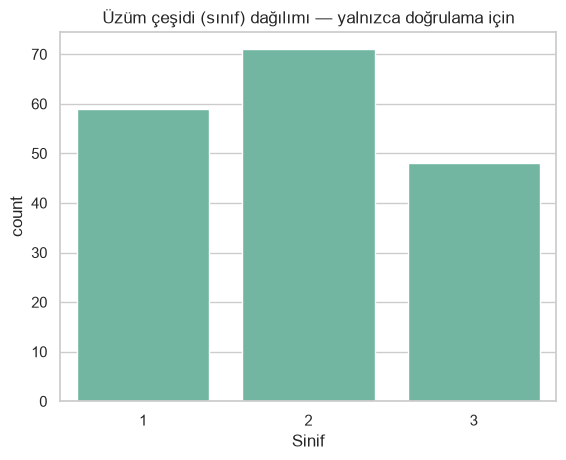

In [6]:
tablo = pd.DataFrame({"Frekans": df["Sinif"].value_counts().sort_index(),
                      "Oran (%)": df["Sinif"].value_counts(normalize=True).sort_index() * 100})
display(tablo)
sns.countplot(data=df, x="Sinif")
plt.title("Üzüm çeşidi (sınıf) dağılımı — yalnızca doğrulama için")
plt.show()

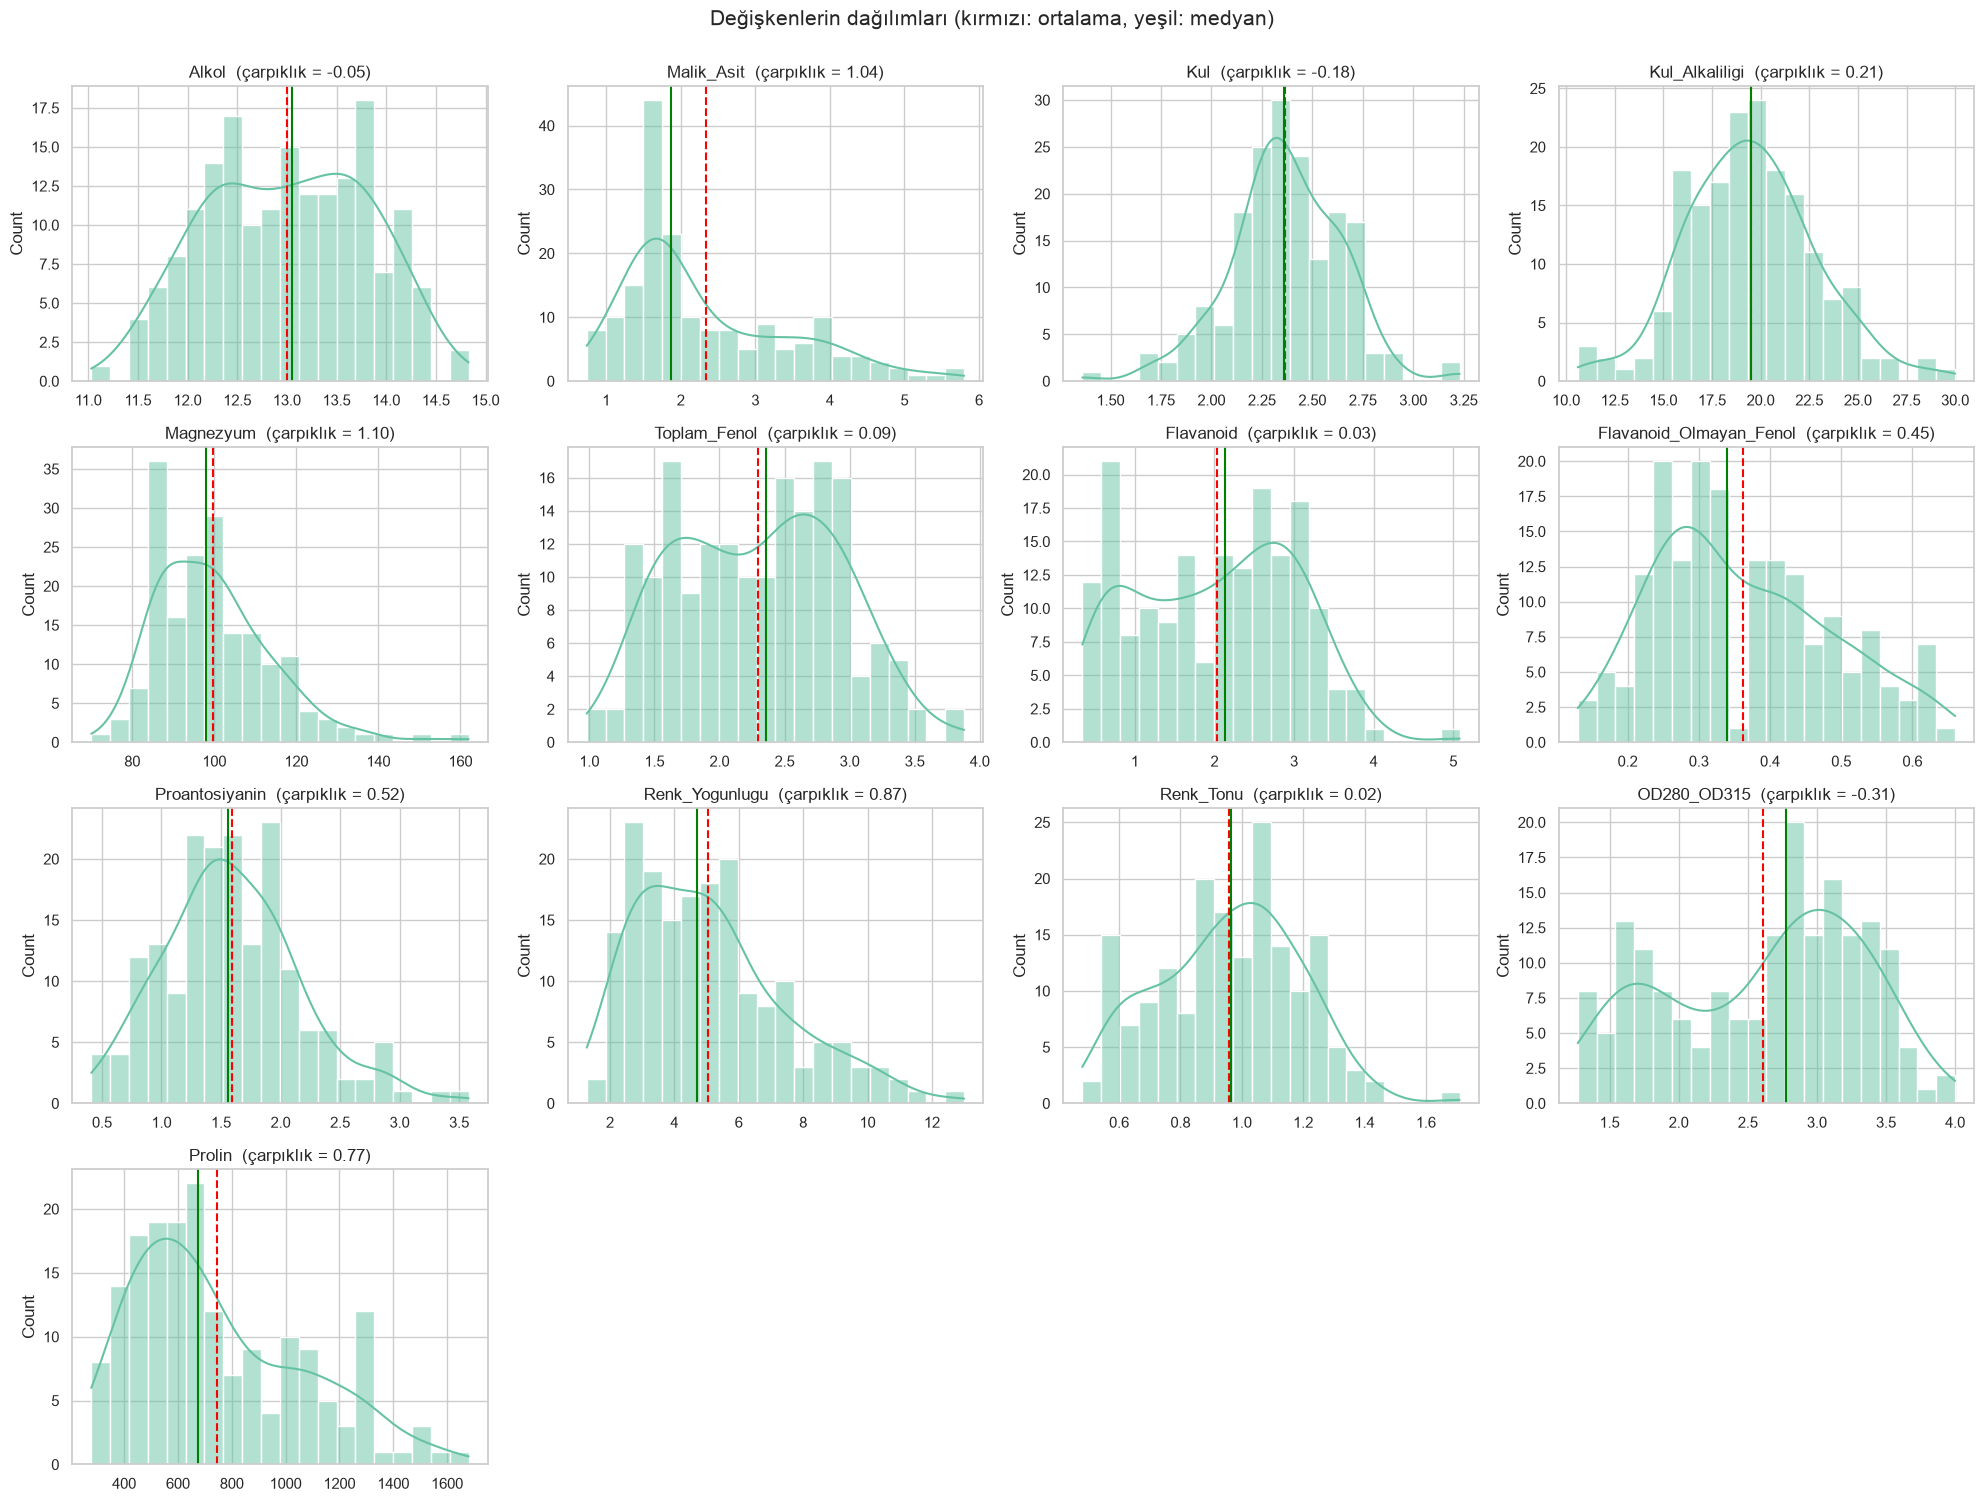

In [7]:
fig, axes = plt.subplots(4, 4, figsize=(20, 15))
for ax, kol in zip(axes.flat, OZELLIKLER):
    sns.histplot(df[kol], kde=True, bins=20, ax=ax)
    ax.axvline(df[kol].mean(), color="red", linestyle="--")
    ax.axvline(df[kol].median(), color="green")
    ax.set_title(f"{kol}  (çarpıklık = {df[kol].skew():.2f})")
    ax.set_xlabel("")
for ax in axes.flat[len(OZELLIKLER):]:
    ax.set_visible(False)
fig.suptitle("Değişkenlerin dağılımları (kırmızı: ortalama, yeşil: medyan)", fontsize=15, y=1.0)
plt.tight_layout()
plt.show()

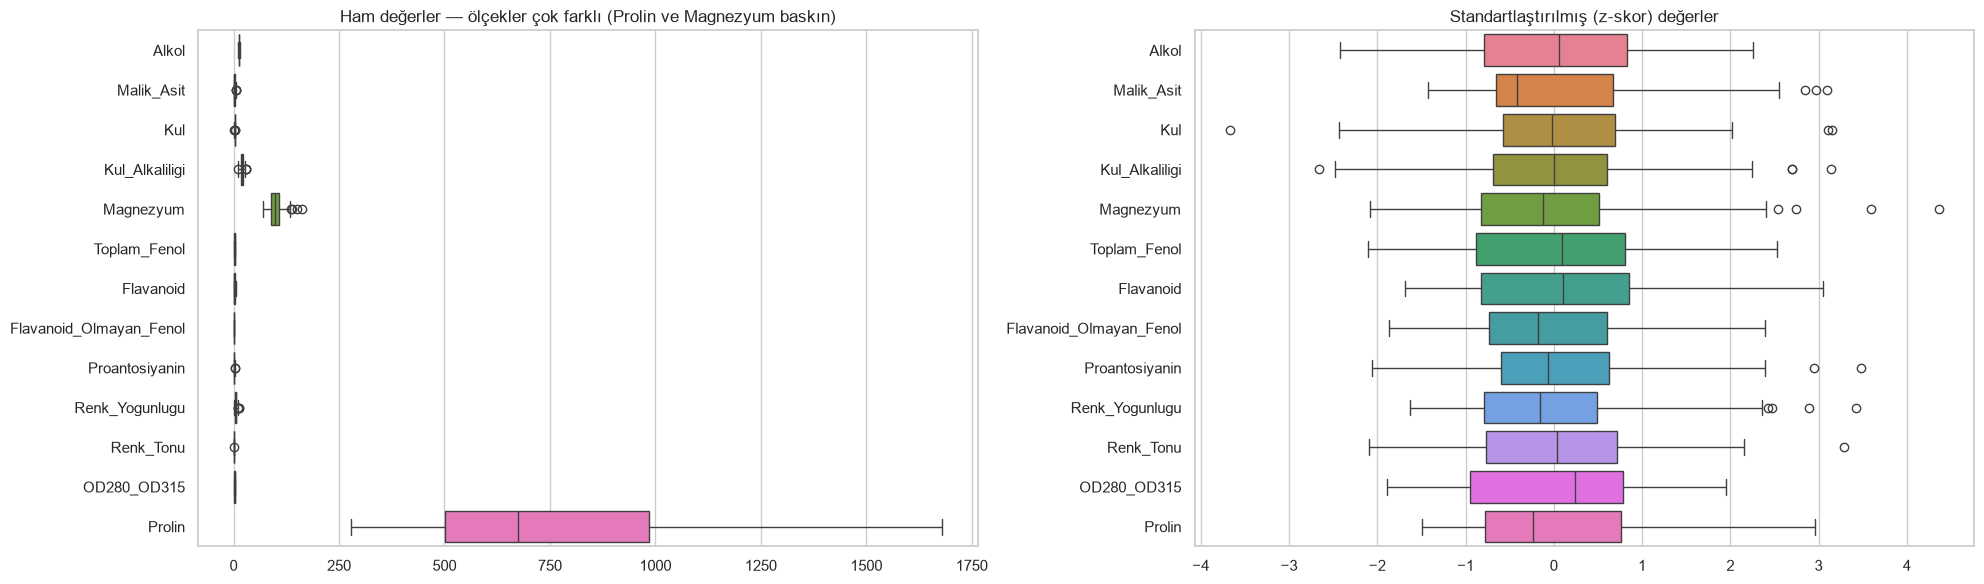

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(20, 6))
sns.boxplot(data=df[OZELLIKLER], orient="h", ax=axes[0])
axes[0].set_title("Ham değerler — ölçekler çok farklı (Prolin ve Magnezyum baskın)")
z = (df[OZELLIKLER] - df[OZELLIKLER].mean()) / df[OZELLIKLER].std()
sns.boxplot(data=z, orient="h", ax=axes[1])
axes[1].set_title("Standartlaştırılmış (z-skor) değerler")
plt.tight_layout()
plt.show()

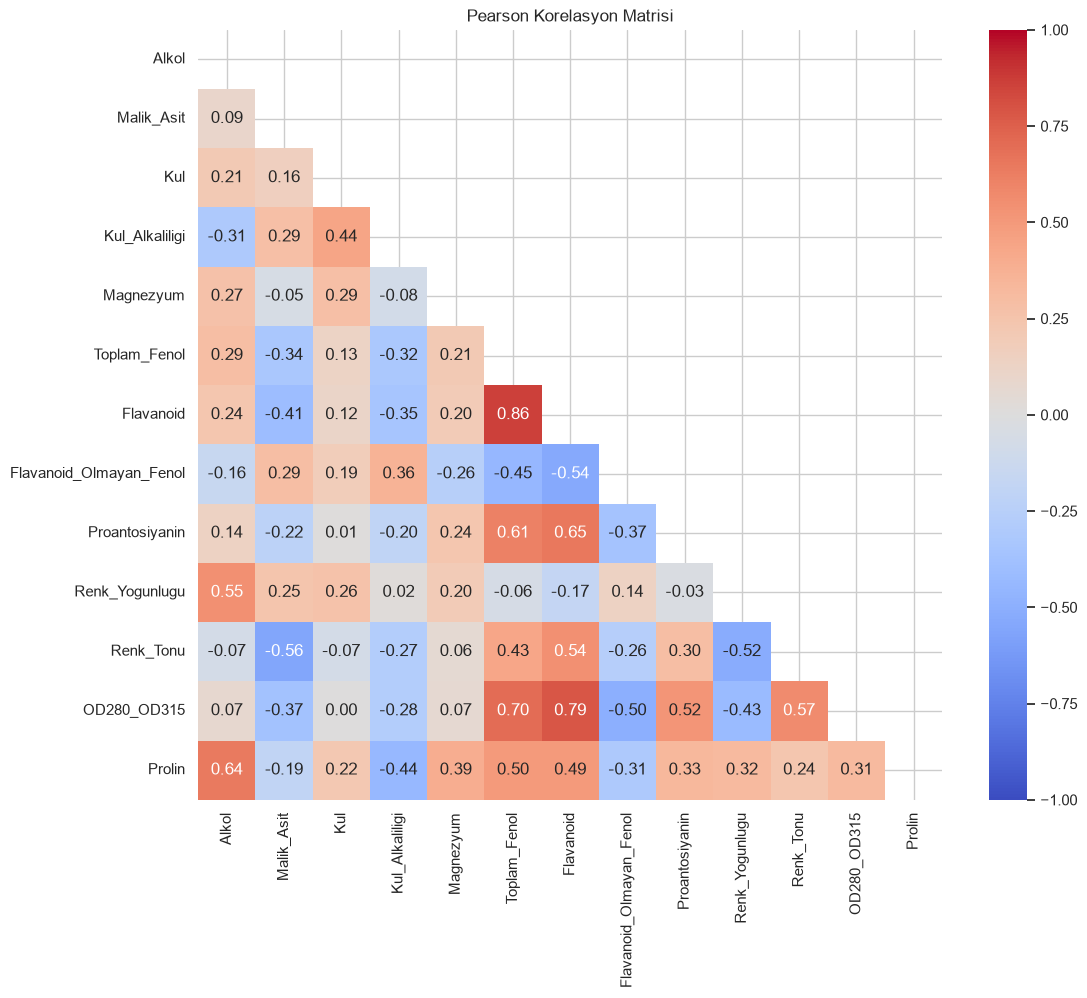

In [9]:
plt.figure(figsize=(12, 10))
maske = np.triu(np.ones((len(OZELLIKLER), len(OZELLIKLER)), dtype=bool))
sns.heatmap(df[OZELLIKLER].corr(), mask=maske, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Pearson Korelasyon Matrisi")
plt.show()

In [10]:
kor = df[OZELLIKLER].corr().where(~np.tril(np.ones((len(OZELLIKLER),) * 2, dtype=bool)))
en_guclu = kor.stack().sort_values(key=abs, ascending=False).head(8).to_frame("r")
en_guclu.index.names = ["Değişken 1", "Değişken 2"]
en_guclu

,,r
Değişken 1,Değişken 2,
Toplam_Fenol,Flavanoid,0.865
Flavanoid,OD280_OD315,0.787
Toplam_Fenol,OD280_OD315,0.700
Flavanoid,Proantosiyanin,0.653
Alkol,Prolin,0.644
Toplam_Fenol,Proantosiyanin,0.612
Renk_Tonu,OD280_OD315,0.565
Malik_Asit,Renk_Tonu,-0.561


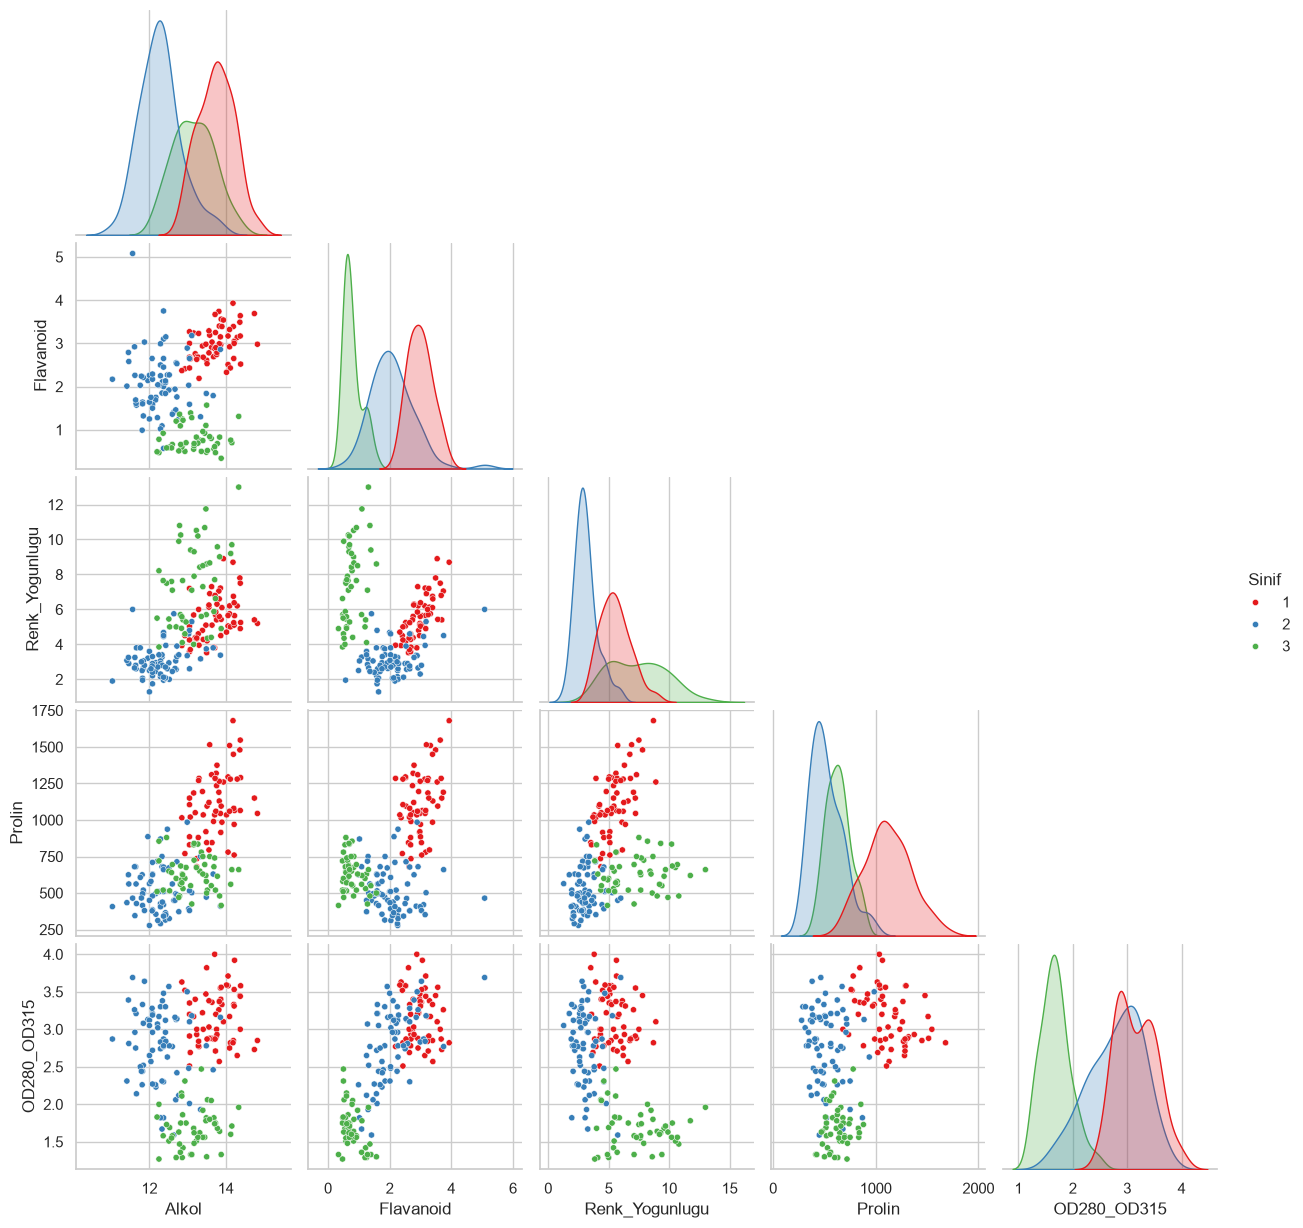

In [11]:
sns.pairplot(df, vars=["Alkol", "Flavanoid", "Renk_Yogunlugu", "Prolin", "OD280_OD315"],
             hue="Sinif", palette="Set1", diag_kind="kde", corner=True, plot_kws={"s": 20})
plt.show()

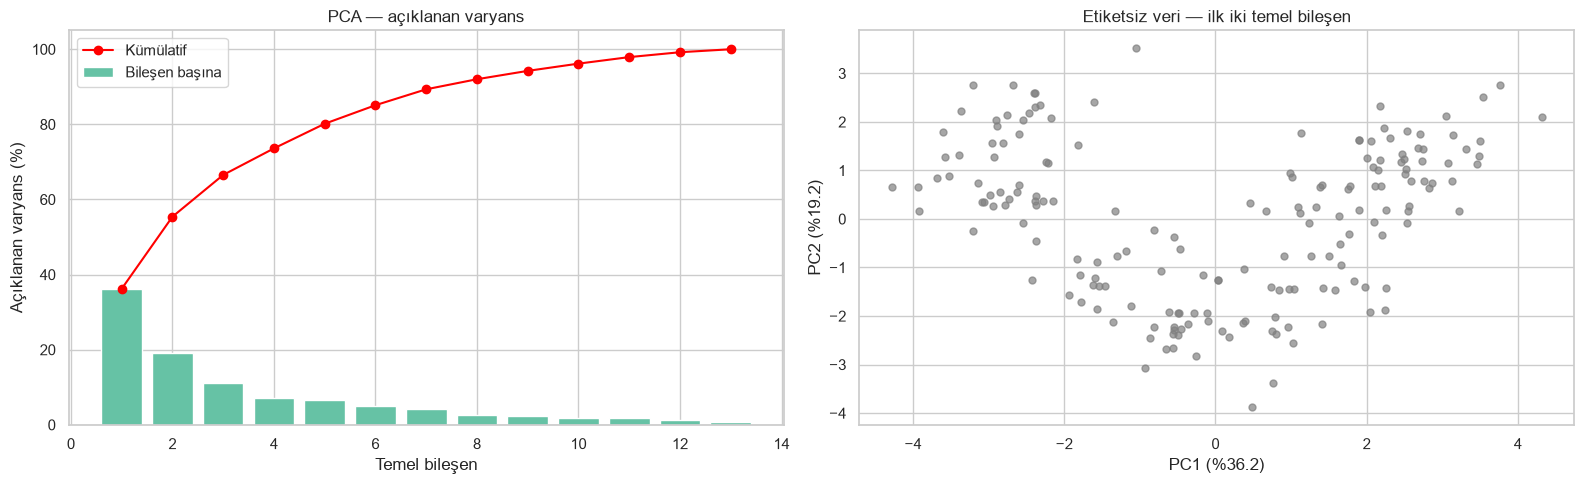

İlk iki bileşen toplam varyansın %55.4'ini açıklıyor.


In [12]:
X_olcekli = StandardScaler().fit_transform(df[OZELLIKLER])
pca_tam = PCA().fit(X_olcekli)
oran = pca_tam.explained_variance_ratio_

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].bar(range(1, 14), oran * 100, label="Bileşen başına")
axes[0].plot(range(1, 14), np.cumsum(oran) * 100, "ro-", label="Kümülatif")
axes[0].set_xlabel("Temel bileşen")
axes[0].set_ylabel("Açıklanan varyans (%)")
axes[0].set_title("PCA — açıklanan varyans")
axes[0].legend()

pc = pca_tam.transform(X_olcekli)
axes[1].scatter(pc[:, 0], pc[:, 1], c="gray", s=25, alpha=0.7)
axes[1].set_xlabel(f"PC1 (%{oran[0] * 100:.1f})")
axes[1].set_ylabel(f"PC2 (%{oran[1] * 100:.1f})")
axes[1].set_title("Etiketsiz veri — ilk iki temel bileşen")
plt.tight_layout()
plt.show()
print(f"İlk iki bileşen toplam varyansın %{oran[:2].sum() * 100:.1f}'ini açıklıyor.")

In [13]:
df[OZELLIKLER].describe().T

,count,mean,std,min,25%,50%,75%,max
Alkol,178.000,13.001,0.812,11.030,12.362,13.050,13.678,14.830
Malik_Asit,178.000,2.336,1.117,0.740,1.603,1.865,3.083,5.800
Kul,178.000,2.367,0.274,1.360,2.210,2.360,2.558,3.230
Kul_Alkaliligi,178.000,19.495,3.340,10.600,17.200,19.500,21.500,30.000
Magnezyum,178.000,99.742,14.282,70.000,88.000,98.000,107.000,162.000
Toplam_Fenol,178.000,2.295,0.626,0.980,1.742,2.355,2.800,3.880
Flavanoid,178.000,2.029,0.999,0.340,1.205,2.135,2.875,5.080
Flavanoid_Olmayan_Fenol,178.000,0.362,0.124,0.130,0.270,0.340,0.438,0.660
Proantosiyanin,178.000,1.591,0.572,0.410,1.250,1.555,1.950,3.580
Renk_Yogunlugu,178.000,5.058,2.318,1.280,3.220,4.690,6.200,13.000


In [14]:
def aciklayici_tablo(d):
    satirlar = {}
    for kol in d.columns:
        s = d[kol]
        q1, q3 = s.quantile([0.25, 0.75])
        iqr = q3 - q1
        satirlar[kol] = {
            "n": s.count(),
            "Ortalama": s.mean(),
            "Medyan": s.median(),
            "Std. Sapma": s.std(),
            "Varyans": s.var(),
            "Std. Hata": stats.sem(s),
            "Değişim Kats. (%)": s.std() / s.mean() * 100,
            "Minimum": s.min(),
            "Q1": q1,
            "Q3": q3,
            "Maksimum": s.max(),
            "Açıklık": s.max() - s.min(),
            "IQR": iqr,
            "Çarpıklık": s.skew(),
            "Basıklık": s.kurt(),
            "Aykırı (1.5·IQR)": int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()),
            "Shapiro-Wilk p": stats.shapiro(s).pvalue,
        }
    return pd.DataFrame(satirlar).T

aciklayici_tablo(df[OZELLIKLER])

,n,Ortalama,Medyan,Std. Sapma,Varyans,Std. Hata,Değişim Kats. (%),Minimum,Q1,Q3,Maksimum,Açıklık,IQR,Çarpıklık,Basıklık,Aykırı (1.5·IQR),Shapiro-Wilk p
Alkol,178.000,13.001,13.050,0.812,0.659,0.061,6.245,11.030,12.362,13.678,14.830,3.800,1.315,-0.051,-0.852,0.000,0.020
Malik_Asit,178.000,2.336,1.865,1.117,1.248,0.084,47.816,0.740,1.603,3.083,5.800,5.060,1.480,1.040,0.299,3.000,0.000
Kul,178.000,2.367,2.360,0.274,0.075,0.021,11.593,1.360,2.210,2.558,3.230,1.870,0.348,-0.177,1.144,3.000,0.039
Kul_Alkaliligi,178.000,19.495,19.500,3.340,11.153,0.250,17.130,10.600,17.200,21.500,30.000,19.400,4.300,0.213,0.488,4.000,0.264
Magnezyum,178.000,99.742,98.000,14.282,203.989,1.071,14.319,70.000,88.000,107.000,162.000,92.000,19.000,1.098,2.105,4.000,0.000
Toplam_Fenol,178.000,2.295,2.355,0.626,0.392,0.047,27.269,0.980,1.742,2.800,3.880,2.900,1.057,0.087,-0.836,0.000,0.004
Flavanoid,178.000,2.029,2.135,0.999,0.998,0.075,49.223,0.340,1.205,2.875,5.080,4.740,1.670,0.025,-0.880,0.000,0.000
Flavanoid_Olmayan_Fenol,178.000,0.362,0.340,0.124,0.015,0.009,34.393,0.130,0.270,0.438,0.660,0.530,0.167,0.450,-0.637,0.000,0.000
Proantosiyanin,178.000,1.591,1.555,0.572,0.328,0.043,35.977,0.410,1.250,1.950,3.580,3.170,0.700,0.517,0.555,2.000,0.014
Renk_Yogunlugu,178.000,5.058,4.690,2.318,5.374,0.174,45.833,1.280,3.220,6.200,13.000,11.720,2.980,0.869,0.382,4.000,0.000


In [15]:
print("Sınıflara (üzüm çeşitlerine) göre ortalamalar — yalnızca bilgi amaçlı")
df.groupby("Sinif")[OZELLIKLER].mean().T

Sınıflara (üzüm çeşitlerine) göre ortalamalar — yalnızca bilgi amaçlı


Sinif,1,2,3
Alkol,13.745,12.279,13.154
Malik_Asit,2.011,1.933,3.334
Kul,2.456,2.245,2.437
Kul_Alkaliligi,17.037,20.238,21.417
Magnezyum,106.339,94.549,99.312
Toplam_Fenol,2.840,2.259,1.679
Flavanoid,2.982,2.081,0.781
Flavanoid_Olmayan_Fenol,0.290,0.364,0.448
Proantosiyanin,1.899,1.630,1.154
Renk_Yogunlugu,5.528,3.087,7.396


In [16]:
K_MIN = 2
K_MAX = 10

assert 2 <= K_MIN < K_MAX < len(df), "Aralık 2 ≤ k_min < k_max < n olmalıdır."
K_ARALIK = list(range(K_MIN, K_MAX + 1))
print(f"Girilen tahmini aralık: k ∈ [{K_MIN}, {K_MAX}]  → {len(K_ARALIK)} farklı k denenecek: {K_ARALIK}")

Girilen tahmini aralık: k ∈ [2, 10]  → 9 farklı k denenecek: [2, 3, 4, 5, 6, 7, 8, 9, 10]


In [17]:
olcekleyici = StandardScaler()
X = olcekleyici.fit_transform(df[OZELLIKLER])

modeller, sonuclar = {}, []
for k in K_ARALIK:
    km = KMeans(n_clusters=k, init="k-means++", n_init=20, max_iter=300, random_state=42).fit(X)
    modeller[k] = km
    sonuclar.append({
        "k": k,
        "WCSS": km.inertia_,
        "Silhouette": silhouette_score(X, km.labels_),
        "Davies-Bouldin": davies_bouldin_score(X, km.labels_),
        "Calinski-Harabasz": calinski_harabasz_score(X, km.labels_),
        "En küçük küme": np.bincount(km.labels_).min(),
        "En büyük küme": np.bincount(km.labels_).max(),
    })
sonuclar = pd.DataFrame(sonuclar).set_index("k")
sonuclar

,WCSS,Silhouette,Davies-Bouldin,Calinski-Harabasz,En küçük küme,En büyük küme
k,,,,,,
2,1658.759,0.259,1.526,69.523,87,91
3,1277.928,0.285,1.389,70.940,51,65
4,1175.352,0.259,1.817,56.189,29,55
5,1107.007,0.232,1.681,47.156,23,55
6,1046.002,0.237,1.554,41.701,5,53
7,981.595,0.204,1.661,38.686,3,54
8,935.201,0.157,1.741,35.805,3,39
9,889.893,0.150,1.708,33.807,4,34
10,845.895,0.144,1.707,32.397,4,27


In [18]:
def dirsek_noktasi(k_degerleri, wcss):
    x = np.array(k_degerleri, dtype=float)
    y = np.array(wcss, dtype=float)
    xn = (x - x.min()) / (x.max() - x.min())
    yn = (y - y.min()) / (y.max() - y.min())
    uzaklik = np.abs(yn - (1 - xn))
    return int(x[np.argmax(uzaklik)])

oylar = pd.Series({
    "Dirsek (WCSS)": dirsek_noktasi(K_ARALIK, sonuclar["WCSS"]),
    "Silhouette (maks.)": sonuclar["Silhouette"].idxmax(),
    "Davies-Bouldin (min.)": sonuclar["Davies-Bouldin"].idxmin(),
    "Calinski-Harabasz (maks.)": sonuclar["Calinski-Harabasz"].idxmax(),
}, name="Önerilen k")

oy_sayisi = oylar.value_counts()
en_cok = oy_sayisi[oy_sayisi == oy_sayisi.max()].index
K_SECILEN = int(oylar["Silhouette (maks.)"] if len(en_cok) > 1 and oylar["Silhouette (maks.)"] in en_cok
                else en_cok[0])

display(oylar.to_frame())
print(f"Oy dağılımı: {dict(oy_sayisi)}")
print(f"\n>>> Girilen [{K_MIN}, {K_MAX}] aralığında seçilen en uygun küme sayısı: k = {K_SECILEN} <<<")

,Önerilen k
Dirsek (WCSS),4
Silhouette (maks.),3
Davies-Bouldin (min.),3
Calinski-Harabasz (maks.),3


Oy dağılımı: {3: np.int64(3), 4: np.int64(1)}

>>> Girilen [2, 10] aralığında seçilen en uygun küme sayısı: k = 3 <<<


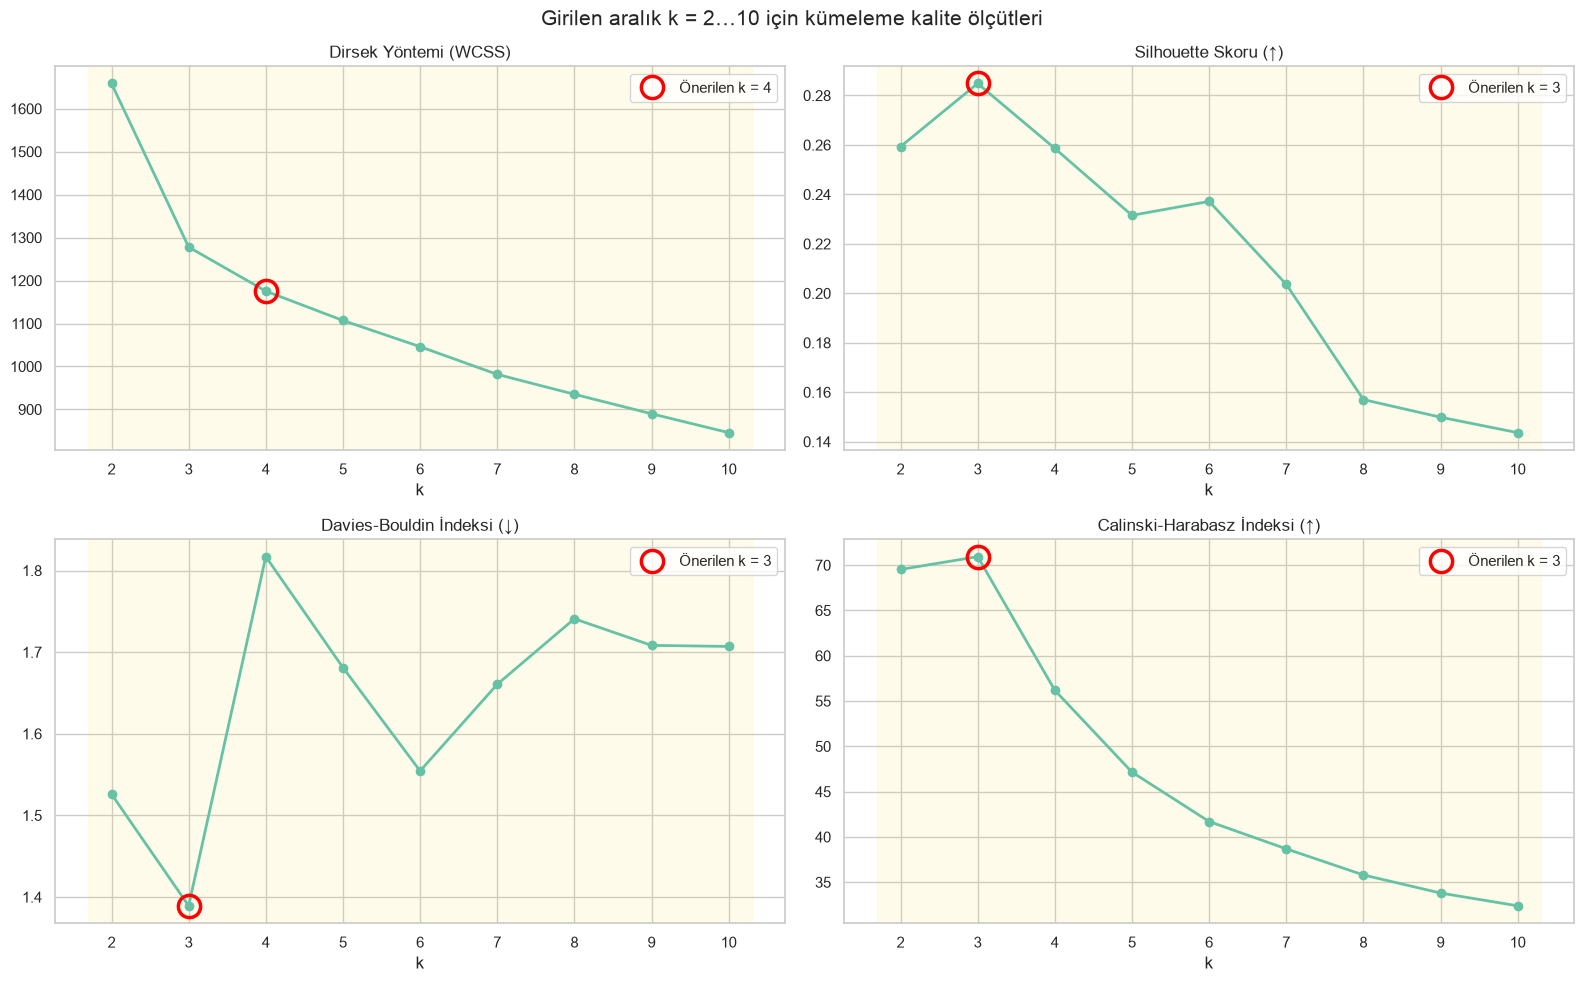

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
grafikler = [("WCSS", "Dirsek Yöntemi (WCSS)", oylar["Dirsek (WCSS)"]),
             ("Silhouette", "Silhouette Skoru (↑)", oylar["Silhouette (maks.)"]),
             ("Davies-Bouldin", "Davies-Bouldin İndeksi (↓)", oylar["Davies-Bouldin (min.)"]),
             ("Calinski-Harabasz", "Calinski-Harabasz İndeksi (↑)", oylar["Calinski-Harabasz (maks.)"])]
for ax, (kol, baslik, onerilen) in zip(axes.flat, grafikler):
    ax.plot(sonuclar.index, sonuclar[kol], "o-", linewidth=2)
    ax.plot(onerilen, sonuclar.loc[onerilen, kol], "o", markersize=16, markerfacecolor="none",
            markeredgecolor="red", markeredgewidth=2.5, label=f"Önerilen k = {onerilen}")
    ax.axvspan(K_MIN - 0.3, K_MAX + 0.3, color="gold", alpha=0.08)
    ax.set_title(baslik)
    ax.set_xlabel("k")
    ax.set_xticks(K_ARALIK)
    ax.legend()
fig.suptitle(f"Girilen aralık k = {K_MIN}…{K_MAX} için kümeleme kalite ölçütleri", fontsize=15)
plt.tight_layout()
plt.show()

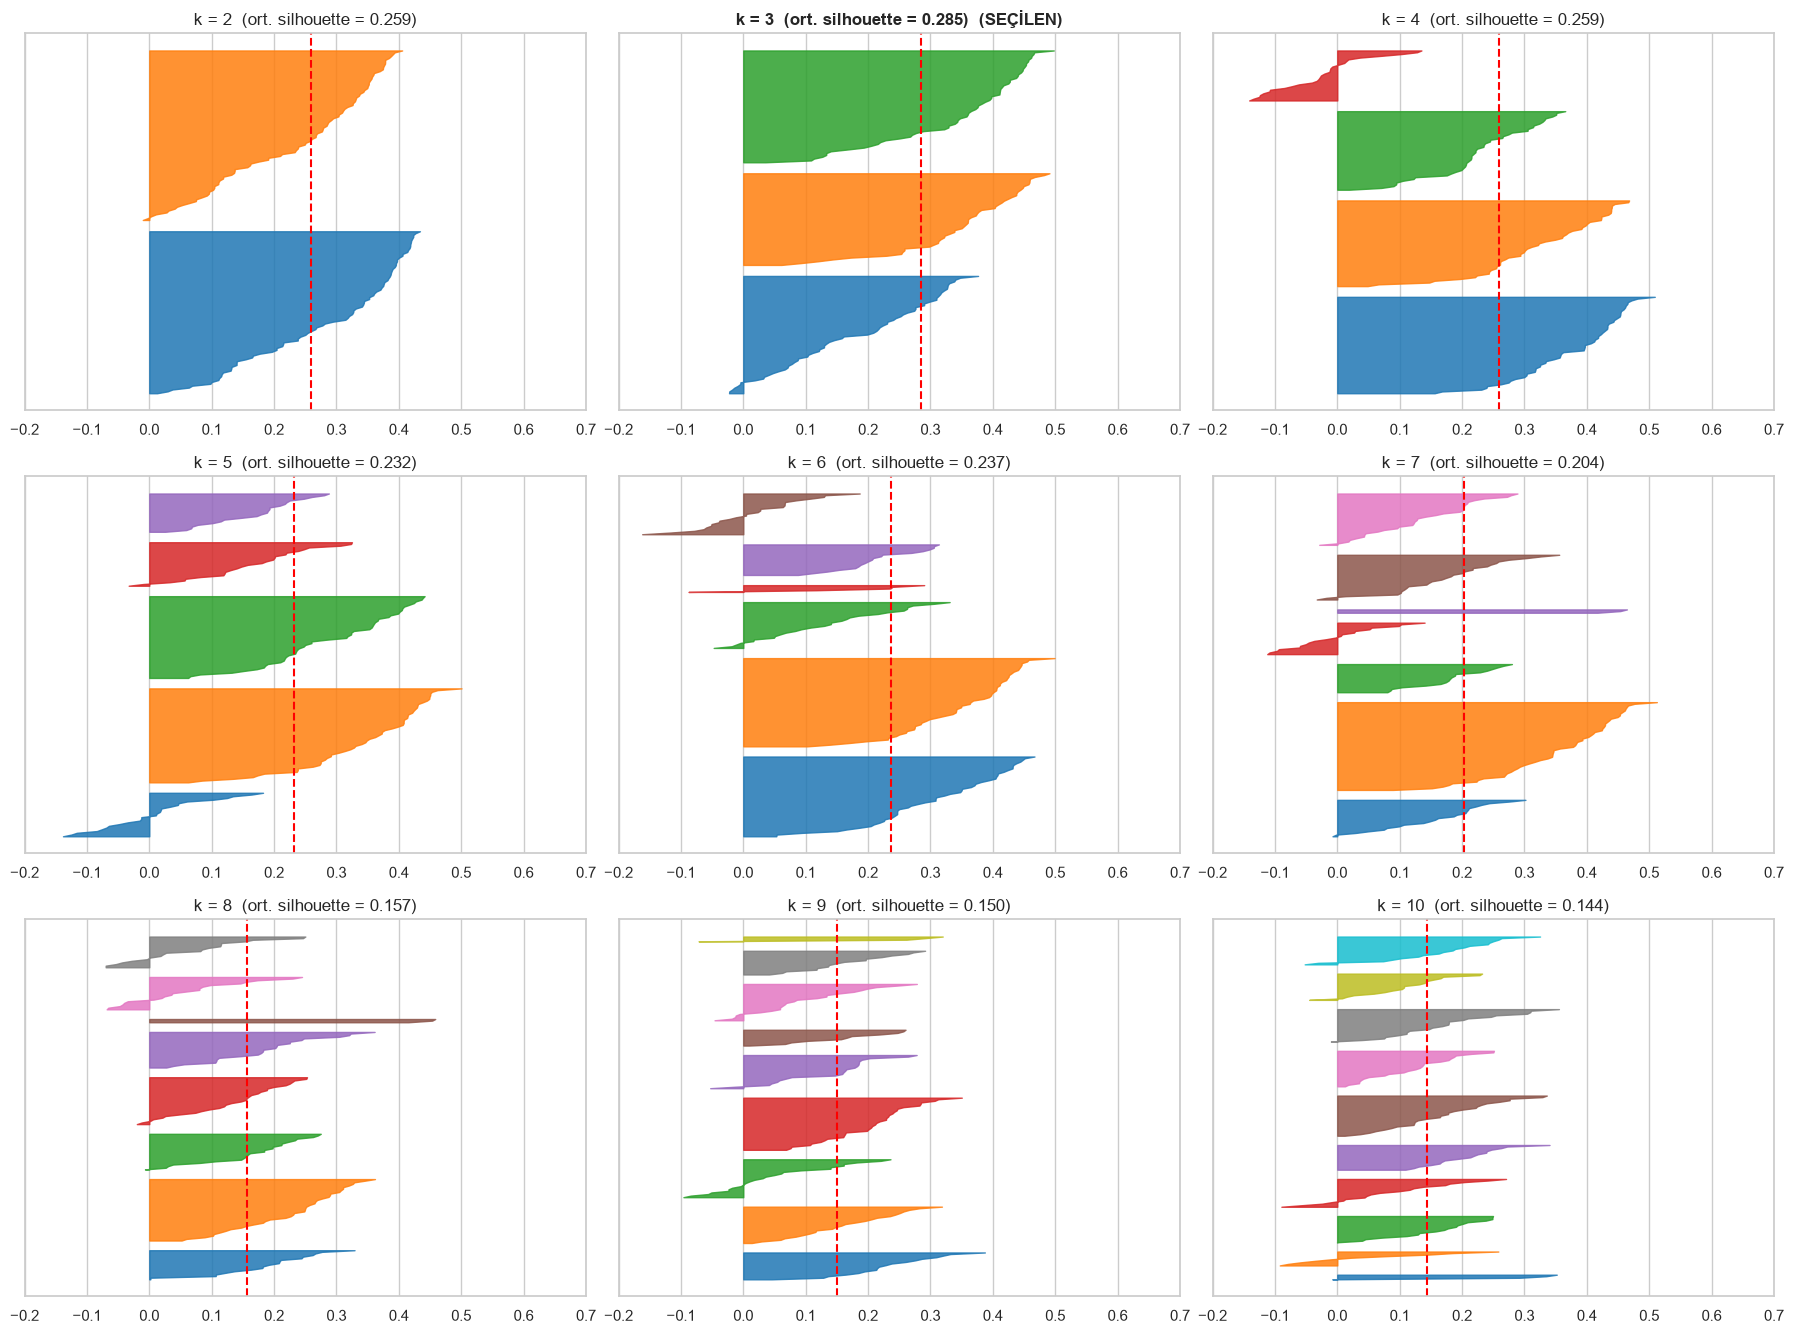

In [20]:
sutun = 3
satir = int(np.ceil(len(K_ARALIK) / sutun))
fig, axes = plt.subplots(satir, sutun, figsize=(18, 4.5 * satir))
for ax, k in zip(axes.flat, K_ARALIK):
    etk = modeller[k].labels_
    sil = silhouette_samples(X, etk)
    renk = sns.color_palette("tab10", k)
    y_alt = 5
    for c in range(k):
        d = np.sort(sil[etk == c])
        ax.fill_betweenx(np.arange(y_alt, y_alt + len(d)), 0, d, color=renk[c], alpha=0.85)
        y_alt += len(d) + 5
    ort = sil.mean()
    ax.axvline(ort, color="red", linestyle="--")
    ax.set_title(f"k = {k}  (ort. silhouette = {ort:.3f})" + ("  (SEÇİLEN)" if k == K_SECILEN else ""),
                 fontweight="bold" if k == K_SECILEN else "normal")
    ax.set_xlim(-0.2, 0.7)
    ax.set_yticks([])
for ax in axes.flat[len(K_ARALIK):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

In [21]:
kmeans = modeller[K_SECILEN]
ham_etiket = kmeans.labels_

merkez_orijinal = pd.DataFrame(olcekleyici.inverse_transform(kmeans.cluster_centers_), columns=OZELLIKLER)
sira = merkez_orijinal["Prolin"].sort_values(ascending=False).index.to_numpy()
yeni_no = {int(eski): yeni + 1 for yeni, eski in enumerate(sira)}
df["Kume"] = pd.Series(ham_etiket).map(yeni_no).values
merkezler = merkez_orijinal.loc[sira].reset_index(drop=True)
merkezler.index = pd.Index(range(1, K_SECILEN + 1), name="Kume")

profil_z = (merkezler - df[OZELLIKLER].mean()) / df[OZELLIKLER].std()
def etiket_uret(satir, n=3):
    en_belirgin = satir.abs().sort_values(ascending=False).index[:n]
    return ", ".join(f"{'↑' if satir[o] > 0 else '↓'}{o}" for o in en_belirgin)
merkezler["Etiket"] = profil_z.apply(etiket_uret, axis=1)
df["Kume_Etiketi"] = df["Kume"].map(merkezler["Etiket"])

print(f"Seçilen k = {K_SECILEN} ile oluşan küme büyüklükleri:")
display(df["Kume"].value_counts().sort_index().to_frame("Gözlem sayısı"))
merkezler[["Etiket"]]

Seçilen k = 3 ile oluşan küme büyüklükleri:


,Gözlem sayısı
Kume,
1,62
2,51
3,65


,Etiket
Kume,
1,"↑Prolin, ↑Flavanoid, ↑Toplam_Fenol"
2,"↓OD280_OD315, ↓Flavanoid, ↓Renk_Tonu"
3,"↓Alkol, ↓Renk_Yogunlugu, ↓Prolin"


In [22]:
CIKTI = "data/wine_etiketli.csv"
df.to_csv(CIKTI, index=False)
print("Etiketlenmiş veri kaydedildi:", CIKTI)
df[["Sinif", "Alkol", "Flavanoid", "Renk_Yogunlugu", "Prolin", "Kume", "Kume_Etiketi"]].sample(10, random_state=3)

Etiketlenmiş veri kaydedildi: data/wine_etiketli.csv


,Sinif,Alkol,Flavanoid,Renk_Yogunlugu,Prolin,Kume,Kume_Etiketi
40,1,13.560,3.290,6.130,795,1,"↑Prolin, ↑Flavanoid, ↑Toplam_Fenol"
53,1,13.770,2.790,6.300,1375,1,"↑Prolin, ↑Flavanoid, ↑Toplam_Fenol"
34,1,13.510,2.530,4.200,1095,1,"↑Prolin, ↑Flavanoid, ↑Toplam_Fenol"
109,2,11.610,2.920,2.650,680,3,"↓Alkol, ↓Renk_Yogunlugu, ↓Prolin"
159,3,13.480,1.100,11.750,620,2,"↓OD280_OD315, ↓Flavanoid, ↓Renk_Tonu"
23,1,12.850,2.370,3.930,1015,1,"↑Prolin, ↑Flavanoid, ↑Toplam_Fenol"
46,1,14.380,3.170,4.900,1065,1,"↑Prolin, ↑Flavanoid, ↑Toplam_Fenol"
72,2,13.490,1.840,3.740,472,3,"↓Alkol, ↓Renk_Yogunlugu, ↓Prolin"
78,2,12.330,1.850,3.400,750,3,"↓Alkol, ↓Renk_Yogunlugu, ↓Prolin"
38,1,13.070,2.640,3.700,1020,1,"↑Prolin, ↑Flavanoid, ↑Toplam_Fenol"


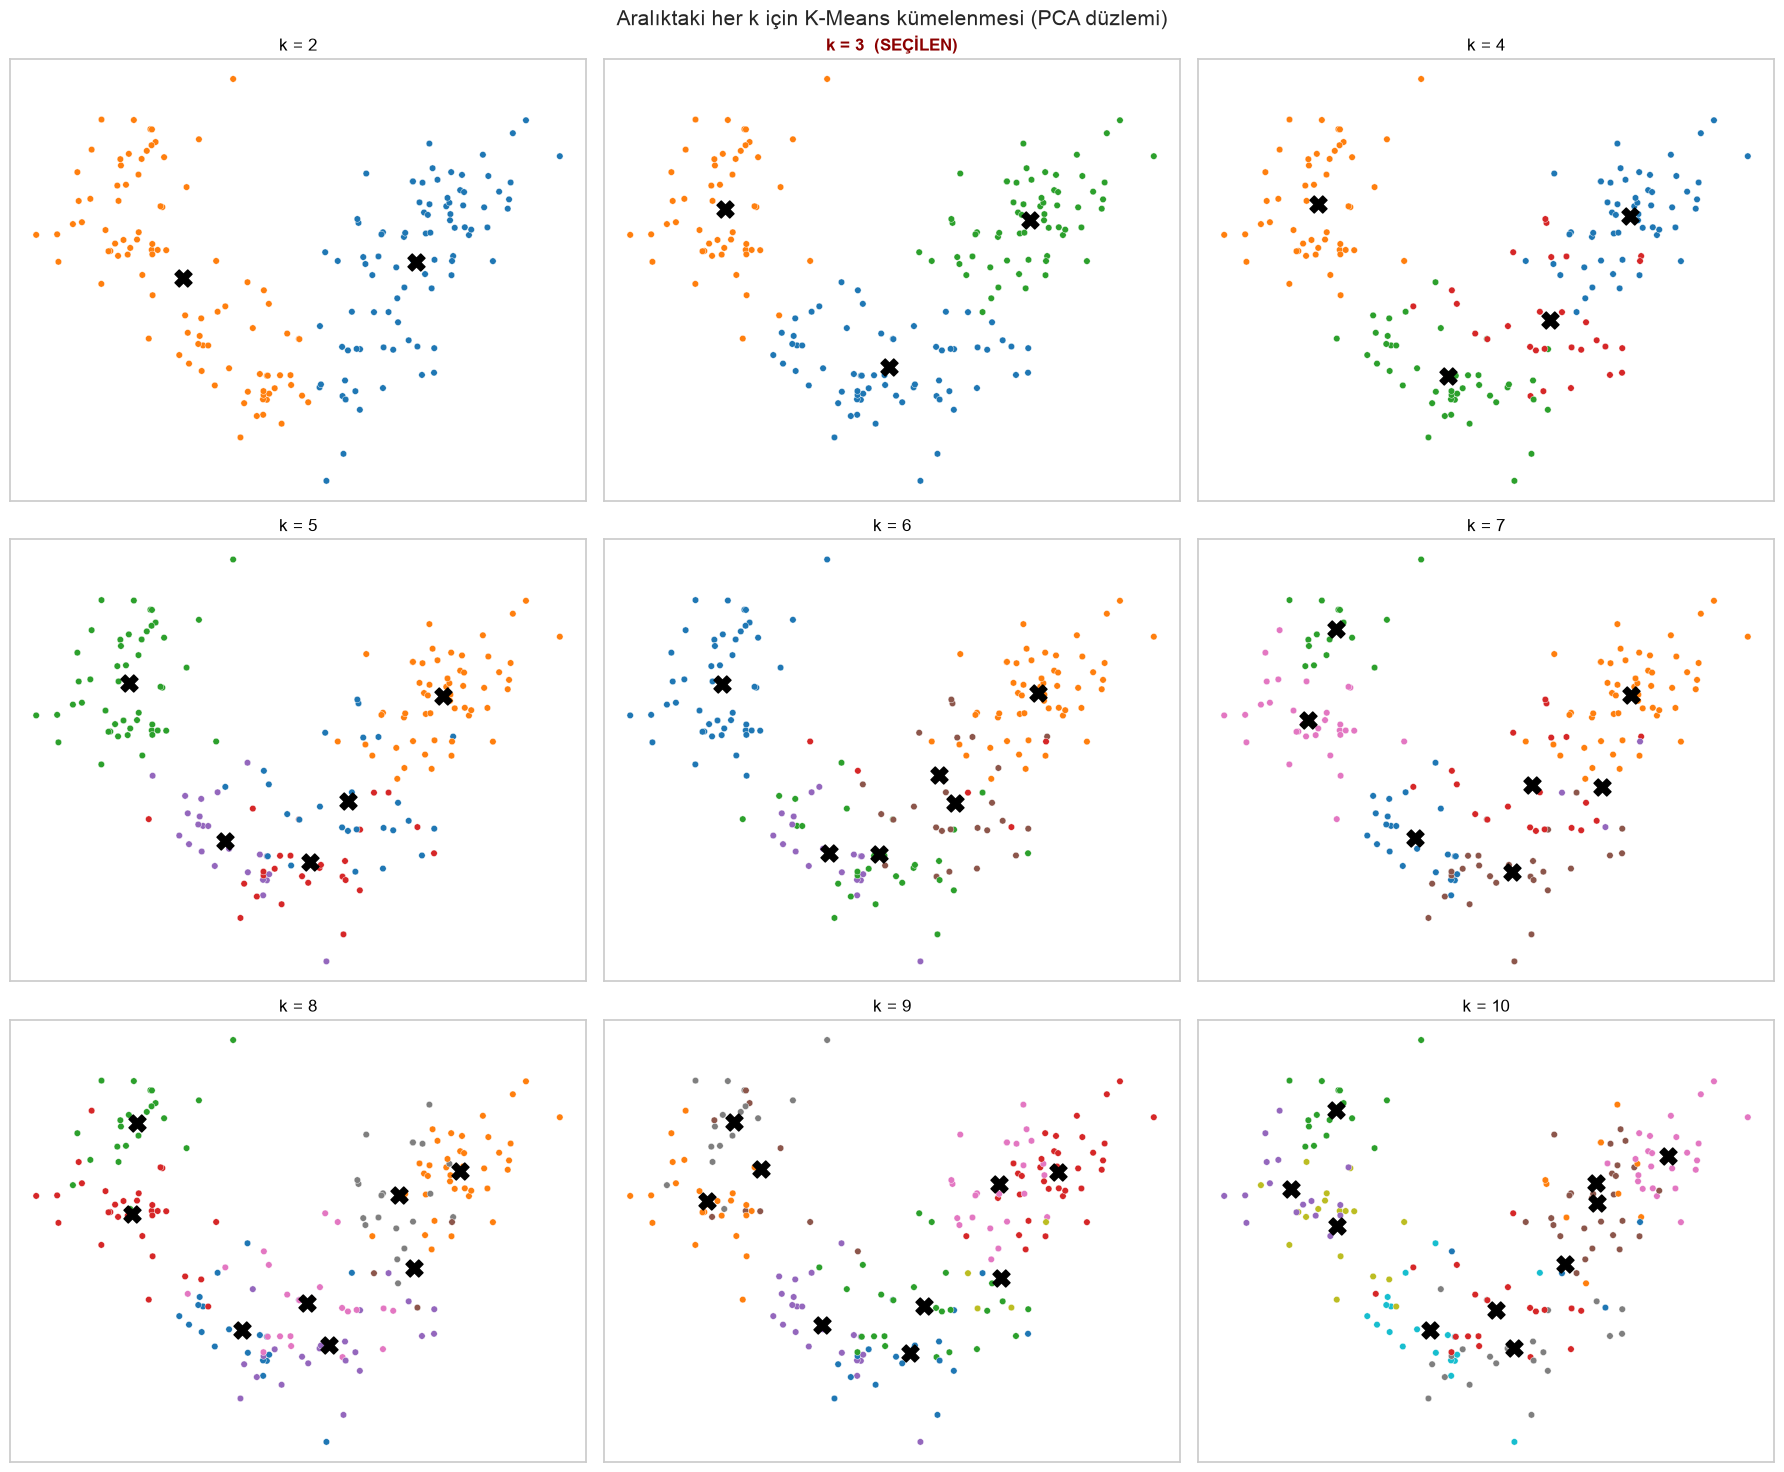

In [23]:
pca = PCA(n_components=2).fit(X)
P = pca.transform(X)
ev = pca.explained_variance_ratio_

fig, axes = plt.subplots(satir, sutun, figsize=(18, 5 * satir))
for ax, k in zip(axes.flat, K_ARALIK):
    km = modeller[k]
    ax.scatter(P[:, 0], P[:, 1], c=km.labels_, cmap="tab10", vmin=0, vmax=9, s=22, edgecolor="white", linewidth=0.3)
    m = pca.transform(km.cluster_centers_)
    ax.scatter(m[:, 0], m[:, 1], c="black", marker="X", s=150)
    ax.set_title(f"k = {k}" + ("  (SEÇİLEN)" if k == K_SECILEN else ""),
                 fontweight="bold" if k == K_SECILEN else "normal",
                 color="darkred" if k == K_SECILEN else "black")
    ax.set_xticks([])
    ax.set_yticks([])
for ax in axes.flat[len(K_ARALIK):]:
    ax.set_visible(False)
fig.suptitle("Aralıktaki her k için K-Means kümelenmesi (PCA düzlemi)", fontsize=15)
plt.tight_layout()
plt.show()

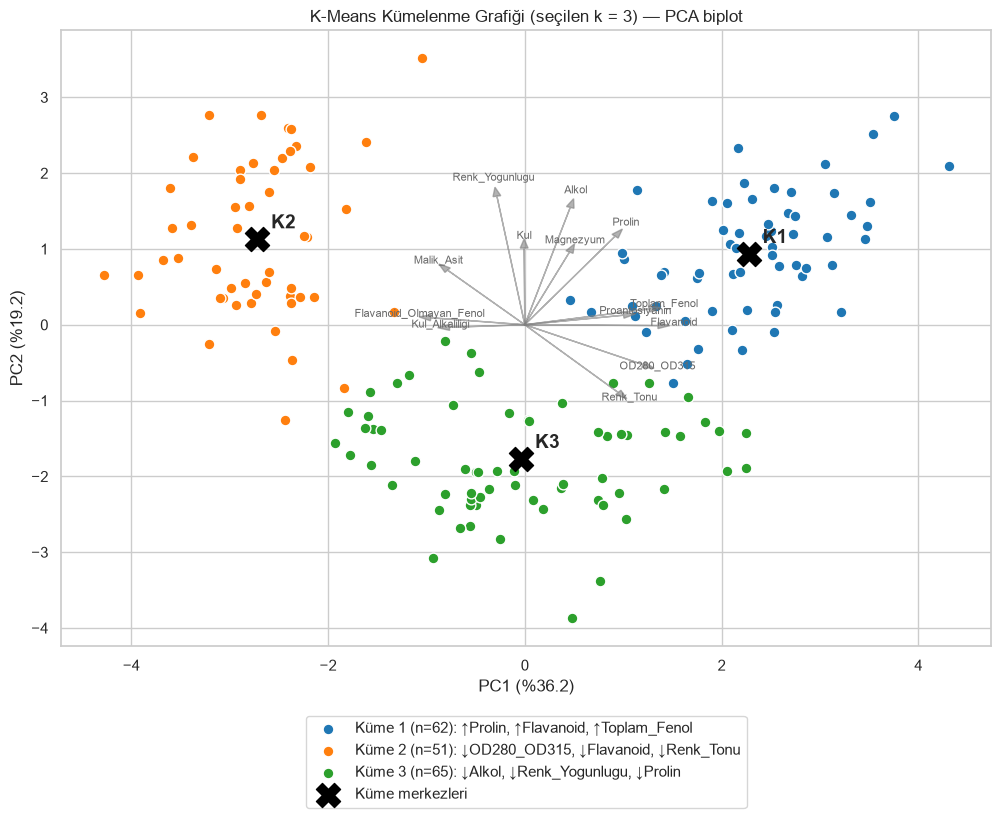

In [24]:
RENKLER = sns.color_palette("tab10", K_SECILEN)
merkez_pca = pca.transform(kmeans.cluster_centers_[sira])

fig, ax = plt.subplots(figsize=(12, 8))
for k in range(1, K_SECILEN + 1):
    maske = df["Kume"].values == k
    ax.scatter(P[maske, 0], P[maske, 1], s=60, color=RENKLER[k - 1], edgecolor="white",
               label=f"Küme {k} (n={maske.sum()}): {merkezler.loc[k, 'Etiket']}")
ax.scatter(merkez_pca[:, 0], merkez_pca[:, 1], c="black", marker="X", s=300, label="Küme merkezleri")
for k, (x0, y0) in enumerate(merkez_pca, start=1):
    ax.annotate(f"K{k}", (x0, y0), xytext=(10, 8), textcoords="offset points", fontsize=14, fontweight="bold")

yuk = pca.components_.T * 3.2
for i, o in enumerate(OZELLIKLER):
    ax.arrow(0, 0, yuk[i, 0], yuk[i, 1], color="gray", alpha=0.6, head_width=0.08)
    ax.text(yuk[i, 0] * 1.12, yuk[i, 1] * 1.12, o, fontsize=8, color="dimgray", ha="center")

ax.set_xlabel(f"PC1 (%{ev[0] * 100:.1f})")
ax.set_ylabel(f"PC2 (%{ev[1] * 100:.1f})")
ax.set_title(f"K-Means Kümelenme Grafiği (seçilen k = {K_SECILEN}) — PCA biplot")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=1)
plt.show()

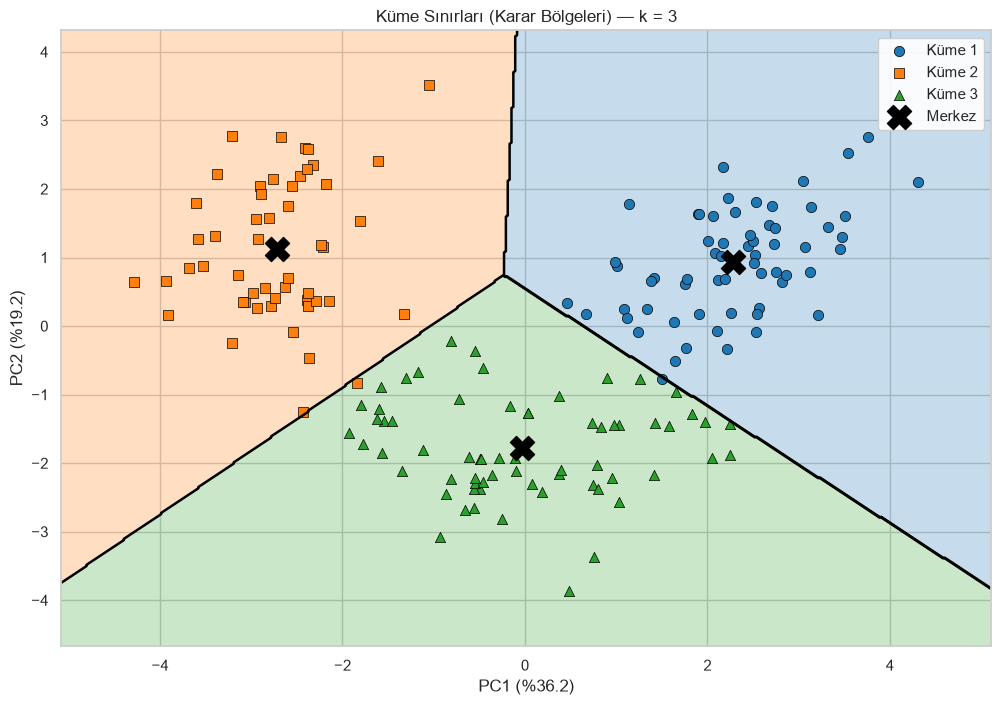

In [25]:
pay = 0.8
xx, yy = np.meshgrid(np.linspace(P[:, 0].min() - pay, P[:, 0].max() + pay, 500),
                     np.linspace(P[:, 1].min() - pay, P[:, 1].max() + pay, 500))
izgara = kmeans.predict(pca.inverse_transform(np.c_[xx.ravel(), yy.ravel()]))
izgara = pd.Series(izgara).map(yeni_no).values.reshape(xx.shape)

fig, ax = plt.subplots(figsize=(12, 8))
ax.contourf(xx, yy, izgara, levels=np.arange(0.5, K_SECILEN + 1.5), cmap=ListedColormap(RENKLER), alpha=0.25)
ax.contour(xx, yy, izgara, levels=np.arange(1.5, K_SECILEN + 0.5), colors="black", linewidths=1.8)
isaret = ["o", "s", "^", "D", "v", "P", "*", "h", "<", ">"]
for k in range(1, K_SECILEN + 1):
    maske = df["Kume"].values == k
    ax.scatter(P[maske, 0], P[maske, 1], s=55, color=RENKLER[k - 1], edgecolor="black", linewidth=0.5,
               marker=isaret[(k - 1) % len(isaret)], label=f"Küme {k}")
ax.scatter(merkez_pca[:, 0], merkez_pca[:, 1], c="black", marker="X", s=300, label="Merkez")
ax.set_xlabel(f"PC1 (%{ev[0] * 100:.1f})")
ax.set_ylabel(f"PC2 (%{ev[1] * 100:.1f})")
ax.set_title(f"Küme Sınırları (Karar Bölgeleri) — k = {K_SECILEN}")
ax.legend(loc="upper right", framealpha=0.9)
plt.show()

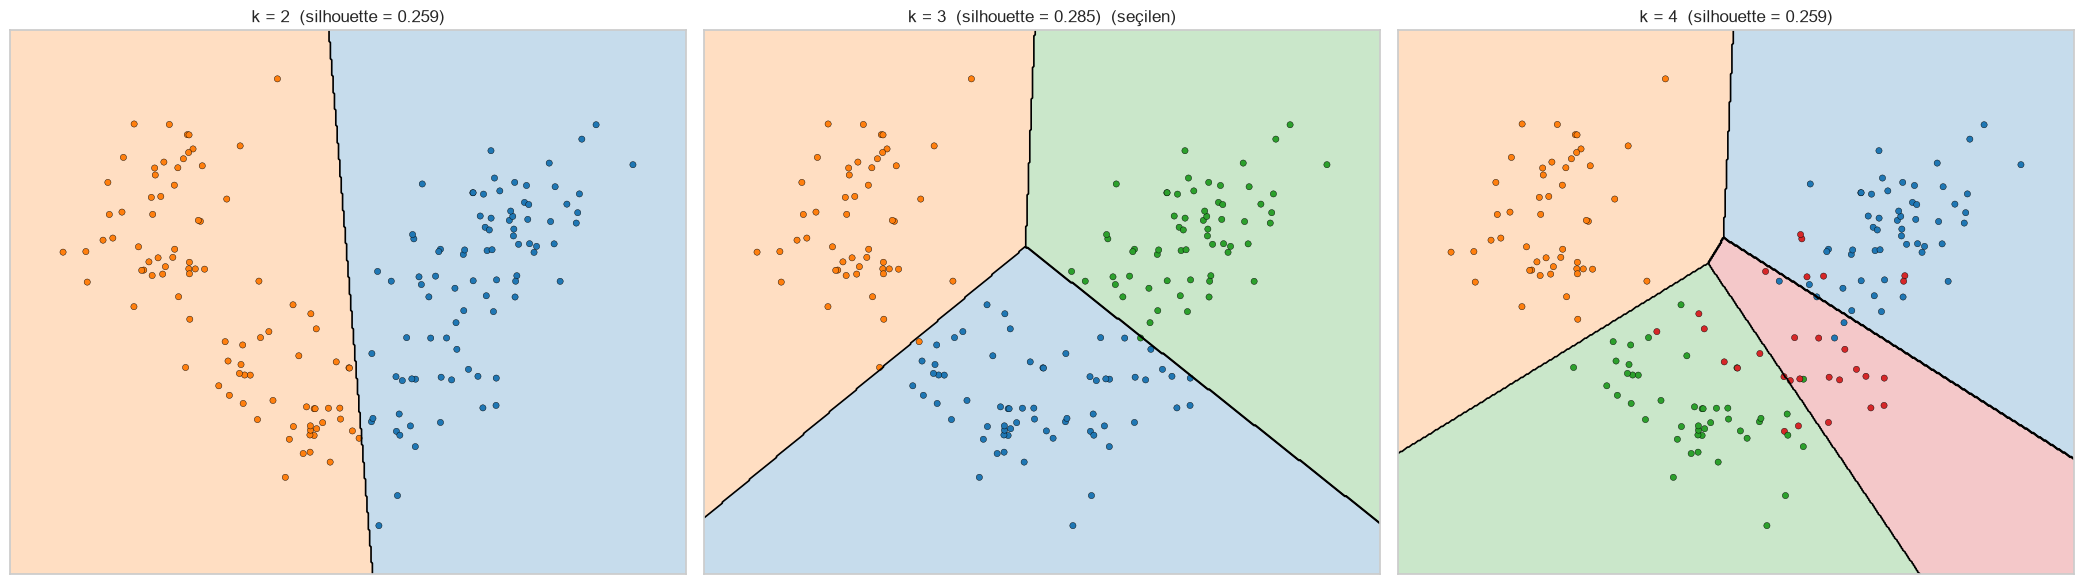

In [26]:
komsu = [k for k in [K_SECILEN - 1, K_SECILEN, K_SECILEN + 1] if k in modeller]
fig, axes = plt.subplots(1, len(komsu), figsize=(7 * len(komsu), 6))
for ax, k in zip(np.atleast_1d(axes), komsu):
    km = modeller[k]
    z = km.predict(pca.inverse_transform(np.c_[xx.ravel(), yy.ravel()])).reshape(xx.shape)
    ax.contourf(xx, yy, z, levels=np.arange(-0.5, k + 0.5), cmap="tab10", vmin=0, vmax=9, alpha=0.25)
    ax.contour(xx, yy, z, levels=np.arange(0.5, k - 0.5 + 1e-9), colors="black", linewidths=1.2)
    ax.scatter(P[:, 0], P[:, 1], c=km.labels_, cmap="tab10", vmin=0, vmax=9, s=20, edgecolor="black", linewidth=0.3)
    ax.set_title(f"k = {k}  (silhouette = {sonuclar.loc[k, 'Silhouette']:.3f})" + ("  (seçilen)" if k == K_SECILEN else ""))
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()

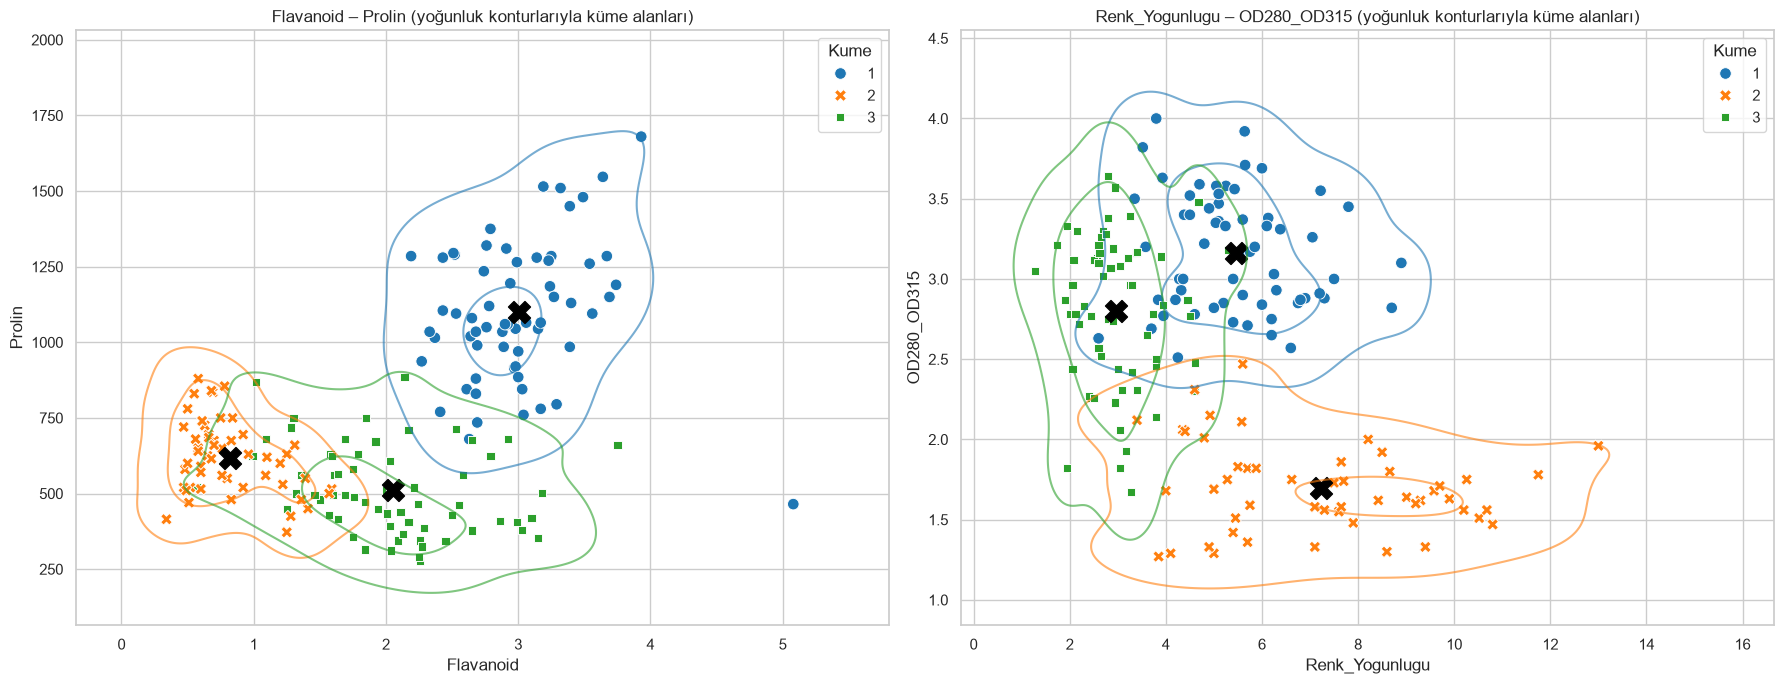

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
for ax, (xk, yk) in zip(axes, [("Flavanoid", "Prolin"), ("Renk_Yogunlugu", "OD280_OD315")]):
    sns.scatterplot(data=df, x=xk, y=yk, hue="Kume", palette=RENKLER, style="Kume", s=70, ax=ax)
    sns.kdeplot(data=df, x=xk, y=yk, hue="Kume", palette=RENKLER, levels=3, alpha=0.6, ax=ax, legend=False)
    ax.scatter(merkezler[xk], merkezler[yk], c="black", marker="X", s=250)
    ax.set_title(f"{xk} – {yk} (yoğunluk konturlarıyla küme alanları)")
plt.tight_layout()
plt.show()

In [28]:
ozet = sonuclar.copy()
ozet["Oy"] = [int((oylar == k).sum()) for k in ozet.index]
ozet["Seçim"] = np.where(ozet.index == K_SECILEN, "★ SEÇİLEN", "")
ozet.style.highlight_max(subset=["Silhouette", "Calinski-Harabasz"], color="lightgreen") \
          .highlight_min(subset=["Davies-Bouldin"], color="lightgreen") \
          .format({"WCSS": "{:.1f}", "Silhouette": "{:.4f}", "Davies-Bouldin": "{:.4f}", "Calinski-Harabasz": "{:.2f}"})

,WCSS,Silhouette,Davies-Bouldin,Calinski-Harabasz,En küçük küme,En büyük küme,Oy,Seçim
k,,,,,,,,
2,1658.8,0.2593,1.5260,69.52,87,91,0,
3,1277.9,0.2849,1.3892,70.94,51,65,3,★ SEÇİLEN
4,1175.4,0.2586,1.8170,56.19,29,55,1,
5,1107.0,0.2315,1.6811,47.16,23,55,0,
6,1046.0,0.2372,1.5544,41.70,5,53,0,
7,981.6,0.2036,1.6606,38.69,3,54,0,
8,935.2,0.1570,1.7409,35.81,3,39,0,
9,889.9,0.1499,1.7083,33.81,4,34,0,
10,845.9,0.1436,1.7070,32.40,4,27,0,


In [29]:
df["Silhouette"] = silhouette_samples(X, ham_etiket)
TSS = ((X - X.mean(axis=0)) ** 2).sum()
WSS = kmeans.inertia_

pd.Series({
    "Gözlem sayısı": len(df),
    "Kümeleme değişkenleri": f"{len(OZELLIKLER)} kimyasal özellik (z-skor)",
    "Algoritma": "K-Means (k-means++, n_init=20)",
    "Girilen aralık": f"[{K_MIN}, {K_MAX}]",
    "Seçilen k": K_SECILEN,
    "Seçim oyu": f"{(oylar == K_SECILEN).sum()} / {len(oylar)} ölçüt",
    "İterasyon sayısı": kmeans.n_iter_,
    "WCSS": round(WSS, 2),
    "BSS / TSS (%)": round((TSS - WSS) / TSS * 100, 2),
    "Silhouette": round(silhouette_score(X, ham_etiket), 4),
    "Davies-Bouldin": round(davies_bouldin_score(X, ham_etiket), 4),
    "Calinski-Harabasz": round(calinski_harabasz_score(X, ham_etiket), 2),
    "Negatif silhouette'li gözlem": int((df["Silhouette"] < 0).sum()),
}).to_frame("Değer")

,Değer
Gözlem sayısı,178
Kümeleme değişkenleri,13 kimyasal özellik (z-skor)
Algoritma,"K-Means (k-means++, n_init=20)"
Girilen aralık,"[2, 10]"
Seçilen k,3
Seçim oyu,3 / 4 ölçüt
İterasyon sayısı,7
WCSS,1277.930
BSS / TSS (%),44.770
Silhouette,0.285


In [30]:
rapor = df.groupby("Kume").agg(
    Etiket=("Kume_Etiketi", "first"),
    Gozlem=("Sinif", "size"),
    Oran_Yuzde=("Sinif", lambda s: len(s) / len(df) * 100),
    Silhouette_Ort=("Silhouette", "mean"),
    Silhouette_Min=("Silhouette", "min"),
)
rapor["Merkeze_Ort_Uzaklik"] = [
    np.linalg.norm(X[df["Kume"].values == k] - kmeans.cluster_centers_[sira[k - 1]], axis=1).mean()
    for k in rapor.index
]
rapor

,Etiket,Gozlem,Oran_Yuzde,Silhouette_Ort,Silhouette_Min,Merkeze_Ort_Uzaklik
Kume,,,,,,
1,"↑Prolin, ↑Flavanoid, ↑Toplam_Fenol",62,34.831,0.343,0.035,2.337
2,"↓OD280_OD315, ↓Flavanoid, ↓Renk_Tonu",51,28.652,0.351,0.061,2.445
3,"↓Alkol, ↓Renk_Yogunlugu, ↓Prolin",65,36.517,0.177,-0.023,2.789


In [31]:
print("Küme merkezleri (orijinal birimlerde)")
merkezler[OZELLIKLER].T

Küme merkezleri (orijinal birimlerde)


Kume,1,2,3
Alkol,13.677,13.134,12.251
Malik_Asit,1.998,3.307,1.897
Kul,2.466,2.418,2.231
Kul_Alkaliligi,17.463,21.241,20.063
Magnezyum,107.968,98.667,92.738
Toplam_Fenol,2.848,1.684,2.248
Flavanoid,3.003,0.819,2.050
Flavanoid_Olmayan_Fenol,0.292,0.452,0.358
Proantosiyanin,1.922,1.146,1.624
Renk_Yogunlugu,5.454,7.235,2.973


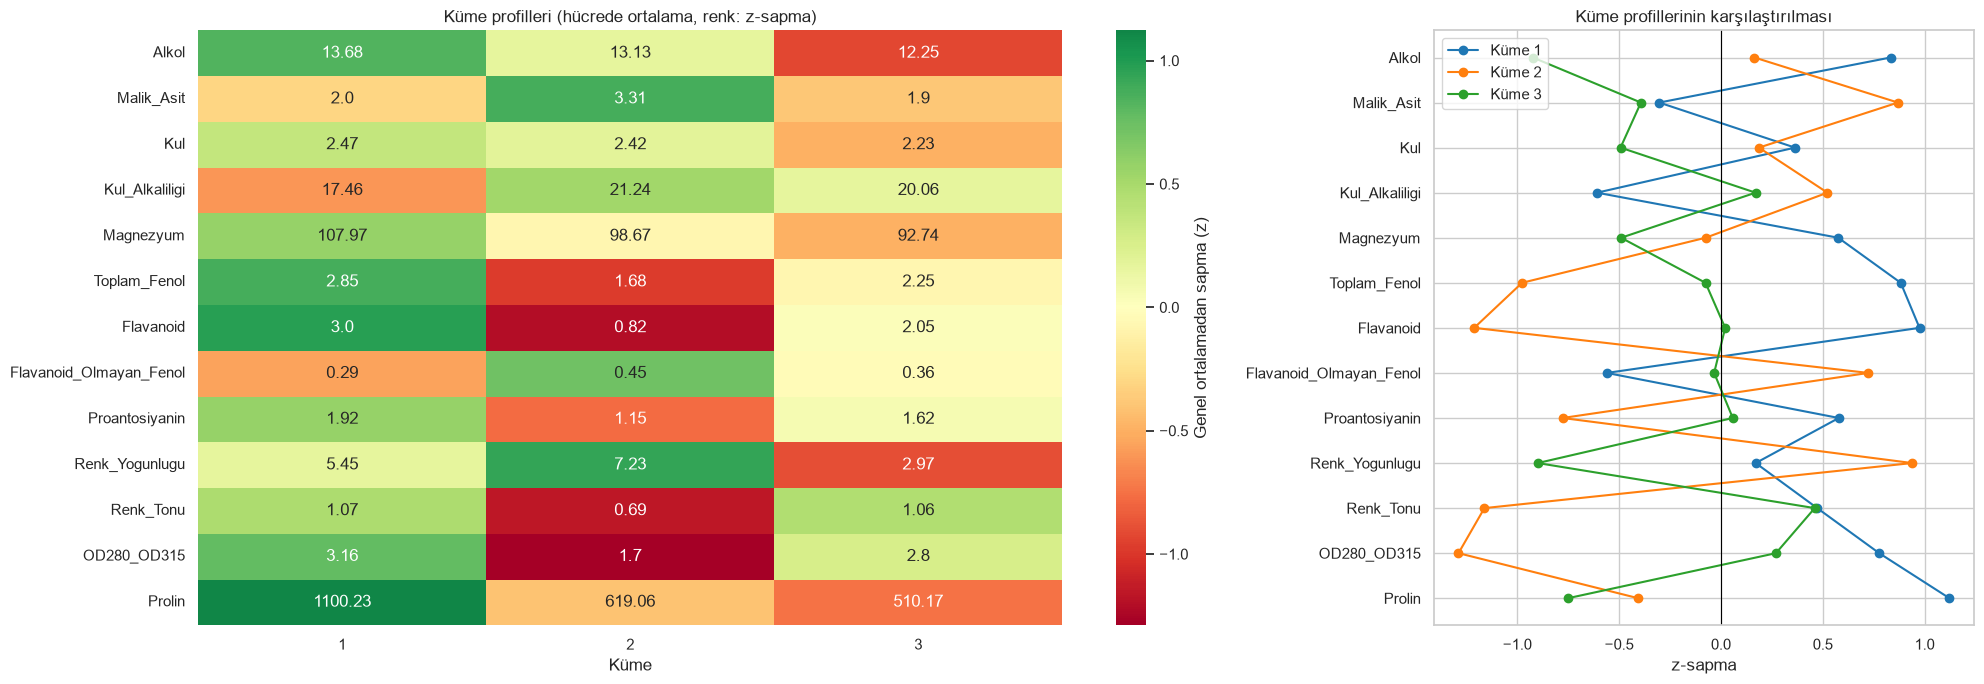

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(20, 7), gridspec_kw={"width_ratios": [2, 1]})
sns.heatmap(profil_z.T, annot=merkezler[OZELLIKLER].T.round(2), fmt="", cmap="RdYlGn", center=0, ax=axes[0],
            cbar_kws={"label": "Genel ortalamadan sapma (z)"})
axes[0].set_title("Küme profilleri (hücrede ortalama, renk: z-sapma)")
axes[0].set_xlabel("Küme")

for k in range(1, K_SECILEN + 1):
    axes[1].plot(profil_z.loc[k].values, range(len(OZELLIKLER)), "o-", color=RENKLER[k - 1], label=f"Küme {k}")
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_yticks(range(len(OZELLIKLER)))
axes[1].set_yticklabels(OZELLIKLER)
axes[1].invert_yaxis()
axes[1].set_xlabel("z-sapma")
axes[1].set_title("Küme profillerinin karşılaştırılması")
axes[1].legend()
plt.tight_layout()
plt.show()

In [33]:
ayrim = []
for o in OZELLIKLER:
    gruplar = [df.loc[df["Kume"] == k, o] for k in range(1, K_SECILEN + 1)]
    h, p = stats.kruskal(*gruplar)
    ss_b = sum(len(g) * (g.mean() - df[o].mean()) ** 2 for g in gruplar)
    ss_t = ((df[o] - df[o].mean()) ** 2).sum()
    ayrim.append({"Değişken": o, "Kruskal-Wallis H": h, "p-değeri": p, "η² (açıklanan varyans)": ss_b / ss_t})
ayrim = pd.DataFrame(ayrim).set_index("Değişken").sort_values("η² (açıklanan varyans)", ascending=False)
ayrim

,Kruskal-Wallis H,p-değeri,η² (açıklanan varyans)
Değişken,,,
Flavanoid,133.285,0.000,0.756
OD280_OD315,112.363,0.000,0.717
Prolin,117.467,0.000,0.696
Alkol,101.947,0.000,0.564
Renk_Yogunlugu,114.730,0.000,0.561
Toplam_Fenol,99.249,0.000,0.550
Renk_Tonu,94.715,0.000,0.545
Malik_Asit,51.263,0.000,0.306
Proantosiyanin,65.260,0.000,0.293


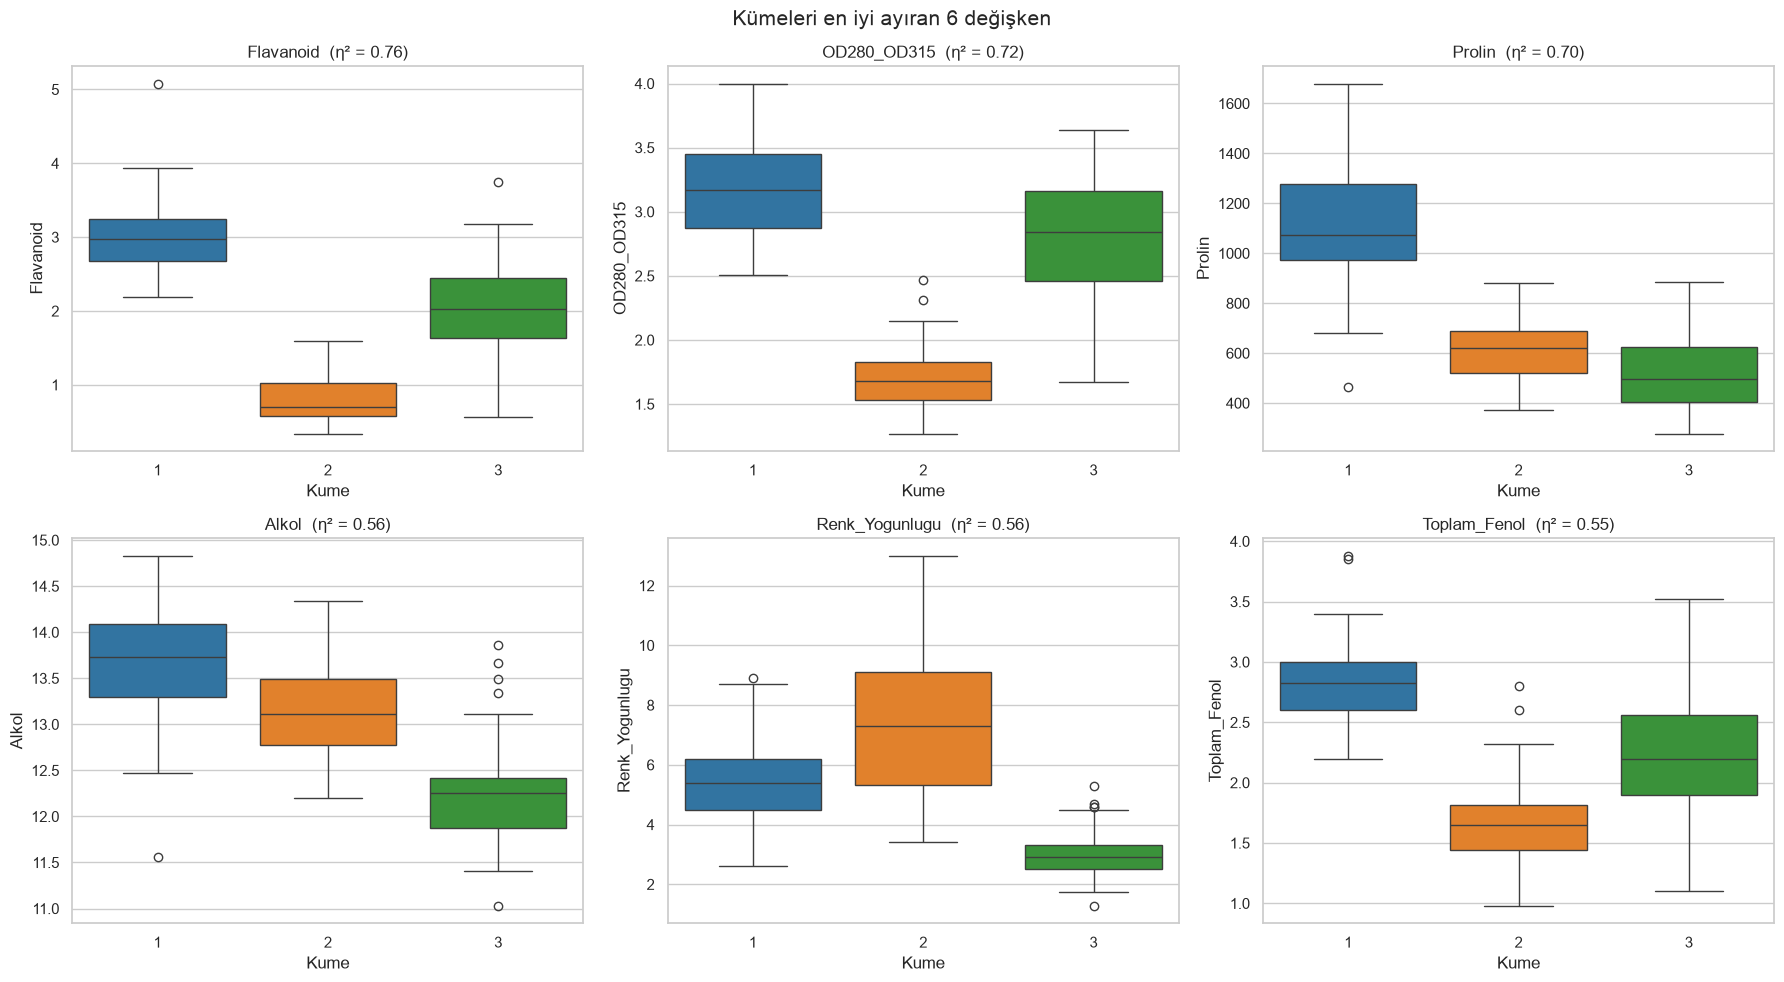

In [34]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, o in zip(axes.flat, ayrim.index[:6]):
    sns.boxplot(data=df, x="Kume", y=o, hue="Kume", palette=RENKLER, legend=False, ax=ax)
    ax.set_title(f"{o}  (η² = {ayrim.loc[o, 'η² (açıklanan varyans)']:.2f})")
fig.suptitle("Kümeleri en iyi ayıran 6 değişken", fontsize=15)
plt.tight_layout()
plt.show()

In [35]:
capraz = pd.crosstab(df["Sinif"], df["Kume"], margins=True, margins_name="Toplam")
capraz.index.name = "Gerçek Sınıf"
capraz.columns.name = "Küme"
display(capraz)

ari = adjusted_rand_score(df["Sinif"], df["Kume"])
nmi = normalized_mutual_info_score(df["Sinif"], df["Kume"])
cm = confusion_matrix(df["Sinif"], df["Kume"])
satir_i, sutun_i = linear_sum_assignment(-cm)
dogru = cm[satir_i, sutun_i].sum()
saflik = pd.crosstab(df["Kume"], df["Sinif"]).max(axis=1).sum() / len(df)

print(f"Düzeltilmiş Rand İndeksi (ARI)        : {ari:.4f}   (1 = tam örtüşme, 0 = rastgele)")
print(f"Normalleştirilmiş Karşılıklı Bilgi    : {nmi:.4f}")
print(f"Saflık (purity)                       : {saflik:.4f}")
print(f"En iyi eşleşmeyle doğru etiketlenen   : {dogru} / {len(df)}  (%{dogru / len(df) * 100:.2f})")

Küme,1,2,3,Toplam
Gerçek Sınıf,,,,
1,59,0,0,59
2,3,3,65,71
3,0,48,0,48
Toplam,62,51,65,178


Düzeltilmiş Rand İndeksi (ARI)        : 0.8975   (1 = tam örtüşme, 0 = rastgele)
Normalleştirilmiş Karşılıklı Bilgi    : 0.8759
Saflık (purity)                       : 0.9663
En iyi eşleşmeyle doğru etiketlenen   : 172 / 178  (%96.63)


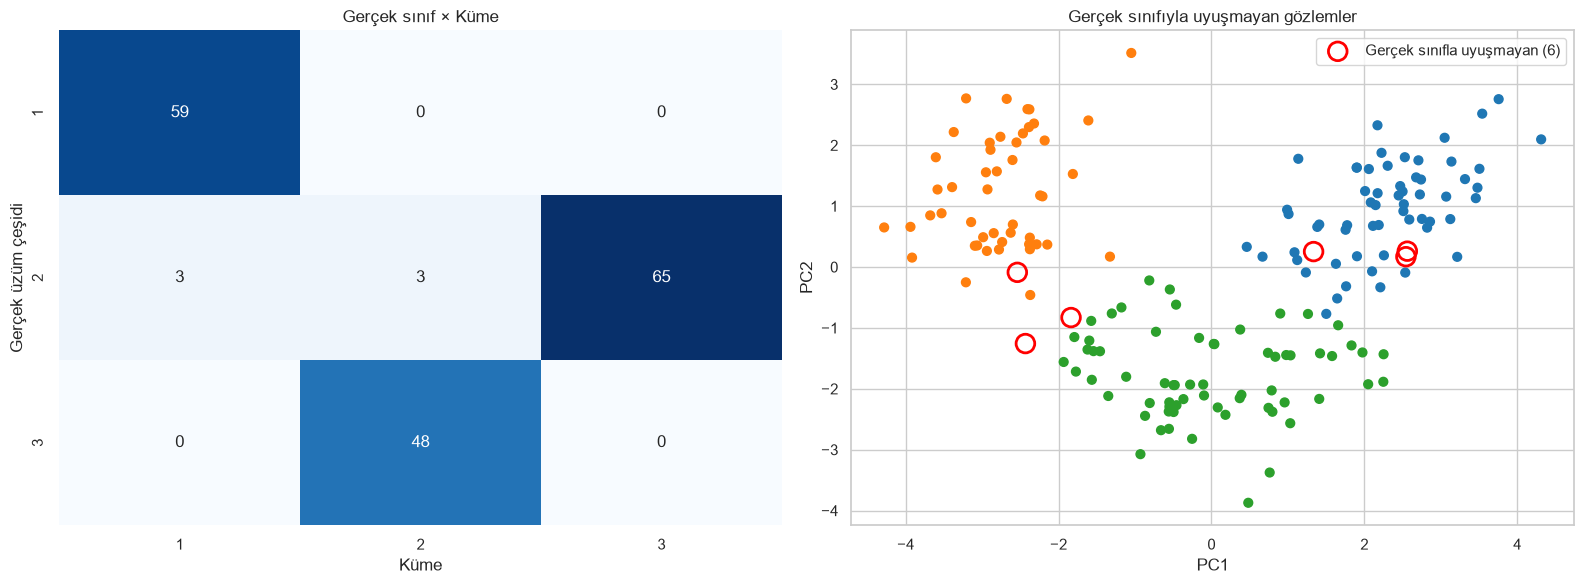

,Sinif,Kume,Silhouette,Alkol,Flavanoid,Renk_Yogunlugu,Prolin
61,2,2,0.061,12.640,1.410,5.750,450
73,2,1,0.140,12.990,2.890,3.350,985
83,2,2,0.229,13.050,1.590,4.800,515
95,2,1,0.113,12.470,2.270,2.600,937
118,2,2,0.092,12.770,1.250,3.400,372
121,2,1,0.035,11.560,5.080,6.000,465


In [36]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(pd.crosstab(df["Sinif"], df["Kume"]), annot=True, fmt="d", cmap="Blues", ax=axes[0], cbar=False)
axes[0].set_title("Gerçek sınıf × Küme")
axes[0].set_xlabel("Küme")
axes[0].set_ylabel("Gerçek üzüm çeşidi")

esles = {sutun_i[i] + 1: satir_i[i] + 1 for i in range(len(satir_i))}
yanlis = df["Kume"].map(esles) != df["Sinif"]
axes[1].scatter(P[~yanlis, 0], P[~yanlis, 1], c=[RENKLER[k - 1] for k in df.loc[~yanlis, "Kume"]], s=40)
axes[1].scatter(P[yanlis, 0], P[yanlis, 1], facecolor="none", edgecolor="red", s=180, linewidth=2,
                label=f"Gerçek sınıfla uyuşmayan ({yanlis.sum()})")
axes[1].set_xlabel("PC1")
axes[1].set_ylabel("PC2")
axes[1].set_title("Gerçek sınıfıyla uyuşmayan gözlemler")
axes[1].legend()
plt.tight_layout()
plt.show()

df.loc[yanlis, ["Sinif", "Kume", "Silhouette", "Alkol", "Flavanoid", "Renk_Yogunlugu", "Prolin"]]

In [37]:
print("=" * 80)
print(f"{'KÜMELENME RAPORU':^80}")
print("=" * 80)
print(f"Yöntem: K-Means | Girilen aralık: k ∈ [{K_MIN}, {K_MAX}] | Seçilen k = {K_SECILEN} | n = {len(df)}")
print("Seçim oyları: " + ", ".join(f"{i} → k={v}" for i, v in oylar.items()))
print(f"Silhouette = {silhouette_score(X, ham_etiket):.3f} | Davies-Bouldin = {davies_bouldin_score(X, ham_etiket):.3f} | "
      f"BSS/TSS = %{(TSS - WSS) / TSS * 100:.1f}")
print(f"Gerçek sınıflarla uyum: ARI = {ari:.3f} | doğru eşleşme = %{dogru / len(df) * 100:.1f}")
print("-" * 80)
for k, r in rapor.iterrows():
    baskin = df.loc[df["Kume"] == k, "Sinif"].value_counts()
    print(f"Küme {k}: {r['Gozlem']} şarap (%{r['Oran_Yuzde']:.1f}) | ort. silhouette = {r['Silhouette_Ort']:.3f}")
    print(f"   Belirgin özellikler: {r['Etiket']}")
    print(f"   Baskın gerçek sınıf: {baskin.index[0]} ({baskin.iloc[0]}/{r['Gozlem']})")
print("=" * 80)

                                KÜMELENME RAPORU                                
Yöntem: K-Means | Girilen aralık: k ∈ [2, 10] | Seçilen k = 3 | n = 178
Seçim oyları: Dirsek (WCSS) → k=4, Silhouette (maks.) → k=3, Davies-Bouldin (min.) → k=3, Calinski-Harabasz (maks.) → k=3
Silhouette = 0.285 | Davies-Bouldin = 1.389 | BSS/TSS = %44.8
Gerçek sınıflarla uyum: ARI = 0.897 | doğru eşleşme = %96.6
--------------------------------------------------------------------------------
Küme 1: 62 şarap (%34.8) | ort. silhouette = 0.343
   Belirgin özellikler: ↑Prolin, ↑Flavanoid, ↑Toplam_Fenol
   Baskın gerçek sınıf: 1 (59/62)
Küme 2: 51 şarap (%28.7) | ort. silhouette = 0.351
   Belirgin özellikler: ↓OD280_OD315, ↓Flavanoid, ↓Renk_Tonu
   Baskın gerçek sınıf: 3 (48/51)
Küme 3: 65 şarap (%36.5) | ort. silhouette = 0.177
   Belirgin özellikler: ↓Alkol, ↓Renk_Yogunlugu, ↓Prolin
   Baskın gerçek sınıf: 2 (65/65)
